# Customer Support Analysis

**Team:** TwoSeven

**Member:** Lucas Liu, Weijun Fan, Shujun Chen

### Background
Many customers tweet a brand for help when their products go wrong. In late 2017, support teams faced two very different surges: Apple’s iOS 11.1 keyboard bug (released Oct 31, fixed Nov 9) and Amazon’s Black Friday (Nov 24) and Cyber Monday (Nov 27).

### Research Problem
1. Do the posting time and wording affect the response speed?
    - Morning or Night
    - Rude or Polite
2. How do support teams react to a planned peak vs an unplanned emergency?
    - Planned Black Friday vs iOS 11.1 keyboard bug
3. Which similar-case search method is more helpful?
    - keywords (TF-IDF) or semantic embeddings

### Delivery
We will deliver a system that accepts a customer's query about the products, and then provide the expected waiting time according to the user's words, posting time and whether it is a peak time, and provide a few related cases for user to review while they are waiting.

## Data Cleaning

### 1. Read Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from langdetect import detect, DetectorFactory # detect language
from tqdm import tqdm # show the data process time

from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

random_seed = 42

W1124 16:18:35.965000 41413 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
df = pd.read_csv("./data/twcs/twcs.csv")
print("Data Shape: ", df.shape)
df.head()

Data Shape:  (2811774, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0


There are 281,1774 data, each row is a tweet, contains 7 columns:
- `tweet_id`: The unique ID of the tweet.
- `author_id`: The ID or account name of the person or support team that posted the tweet.
- `inbound`: Whether the tweet was sent to a company. `True`: a customer message. `False`: a support message.
- `created_at`: The date and time when the tweet was posted.
- `text`: The text of the tweet.
- `response_tweet_id`: The ID(s) of tweets that replied to this tweet, if any.
- `in_response_to_tweet_id`: The ID of the tweet that this tweet replied to, if any.

### 2. Check Missing and Duplicate Data

In [3]:
# Calculate the missing data count
print("Missing Count:")
print(df.isnull().sum())

both_missing = df[df["response_tweet_id"].isnull() & df["in_response_to_tweet_id"].isnull()]
print("Tweets with both IDs missing:", both_missing.shape[0])

Missing Count:
tweet_id                         0
author_id                        0
inbound                          0
created_at                       0
text                             0
response_tweet_id          1040629
in_response_to_tweet_id     794335
dtype: int64
Tweets with both IDs missing: 0


- Missing `response_tweet_id`: last tweet of a series of converstation.
- Missing `in_response_to_tweet_id`: start of a series of conversation.
- Both are missing: neither field records a reply link, so the tweet may be a standalone message.

Missing IDs do not tell us whether the author is a customer or a support account, `inbound` column tell us these.

In [4]:
print("Exact duplicate rows:", df.duplicated().sum())

id_counts = df["tweet_id"].value_counts()
print("Number of repeated tweet IDs:", (id_counts > 1).sum())

Exact duplicate rows: 0
Number of repeated tweet IDs: 0


### 3. Brand Statistics

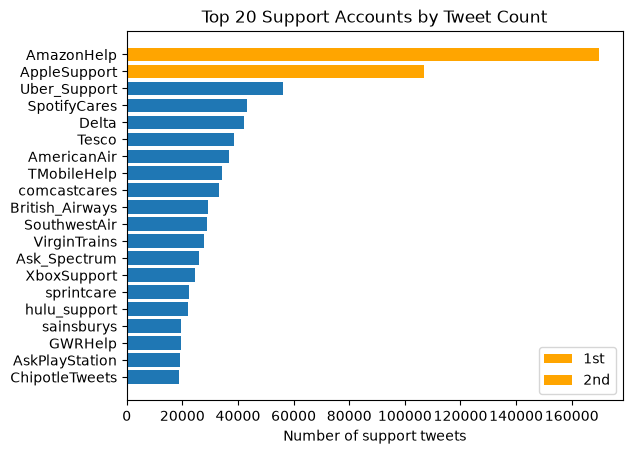

In [5]:
support_tweets = df[df["inbound"] == False]
brand_counts = pd.DataFrame({"Support Tweet Count": support_tweets["author_id"].value_counts()})
top_brands = brand_counts.head(20).sort_values("Support Tweet Count")

plt.barh(top_brands.index, top_brands["Support Tweet Count"])
plt.barh(top_brands.index[-1], top_brands["Support Tweet Count"].iloc[-1], color="orange", label="1st")
plt.barh(top_brands.index[-2], top_brands["Support Tweet Count"].iloc[-2], color="orange", label="2nd")
plt.xlabel("Number of support tweets")
plt.title("Top 20 Support Accounts by Tweet Count")
plt.legend()
plt.show()

The chart shows the 20 support accounts with the most tweets. 

AmazonHelp has the most support tweets, followed by AppleSupport. 
For the rest of this project, we will study only Amazon and Apple, including their support tweets and related customer messages.

Next, we need to assign the related brand to each tweet, then we can delete the other brands' tweets safely.

The Algorithm is:
- first assign those tweet from a support account.
- While there are still tweets without a related brand:
    - propagate the brand that newly assigned last iteration to its parent tweets and its replies.

In [6]:
def find_related_brands(data):
    """Fill unknown brands one reply step at a time using pandas.
    Keep the first assigned brand and return a Series aligned with data.
    """
    # First label the support tweet.
    messages = data[["tweet_id", "in_response_to_tweet_id"]].copy()
    messages["related_brand"] = data["author_id"].where(data["inbound"] == False)
    # Now, only support tweets have the label.
    # new_labels is the latest updated data every iteration.
    new_labels = messages[messages["related_brand"].notna()]
    # unknown is those who haven't been updated.
    unknown = messages[messages["related_brand"].isna()].copy()

    # Only newly labeled tweets need to pass their brand to unknown tweets.
    while not new_labels.empty and not unknown.empty:
        parent_brand = new_labels.set_index("tweet_id")["related_brand"]
        reply_brand = new_labels.groupby("in_response_to_tweet_id")["related_brand"].first()
        # Within each round, use the parent's brand before a reply's brand.
        unknown["related_brand"] = unknown["in_response_to_tweet_id"].map(parent_brand)
        unknown["related_brand"] = unknown["related_brand"].fillna(unknown["tweet_id"].map(reply_brand))
        new_labels = unknown[unknown["related_brand"].notna()]
        messages.loc[new_labels.index, "related_brand"] = new_labels["related_brand"]
        unknown = unknown[unknown["related_brand"].isna()].copy()

    return messages["related_brand"]

cleaned_df = df.copy()

# Add brand labels, then keep tweets related to Amazon or Apple.
cleaned_df["related_brand"] = find_related_brands(cleaned_df)
print("Tweets before filtering:", cleaned_df.shape[0])
cleaned_df = cleaned_df[cleaned_df["related_brand"].isin(["AmazonHelp", "AppleSupport"])]
print("Tweets after filtering:", cleaned_df.shape[0])
cleaned_df.head()

Tweets before filtering: 2811774
Tweets after filtering: 611145


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand
181,269,AmazonHelp,False,Wed Nov 22 09:23:01 +0000 2017,@115770 こんにちは、アマゾン公式です。Fire TV Stickが見れないというのは...,"270,271",272.0,AmazonHelp
182,270,115770,True,Wed Nov 22 09:24:30 +0000 2017,@AmazonHelp ありがとうございます。\n今、電話で主人が対応していただいてます。,NaN,269.0,AmazonHelp
183,271,115770,True,Wed Nov 22 09:30:36 +0000 2017,@AmazonHelp 電話で対応してもらいましたが改良されませんでした。\n保証期間も過ぎ...,273,269.0,AmazonHelp
184,273,AmazonHelp,False,Wed Nov 22 09:40:27 +0000 2017,@115770 カスタマーサービスにてお問い合わせ済みとのことで、お手数をおかけいたしました...,274,271.0,AmazonHelp
185,274,115770,True,Wed Nov 22 09:44:04 +0000 2017,@AmazonHelp こちらこそありがとうございました。,275,273.0,AmazonHelp


### 4. Check Data Types

In [7]:
print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                     int64
author_id                      str
inbound                       bool
created_at                     str
text                           str
response_tweet_id              str
in_response_to_tweet_id    float64
related_brand                  str
dtype: object


- `tweet_id` is `int64`: it contains integer IDs with no missing values.
- `in_response_to_tweet_id` is `float64`: it contains missing values (`NaN`), which regular `int64` cannot store.
- `response_tweet_id` is `str`: some values contain several reply IDs separated by commas, such as `"5,7"`.
- `created_at` is `str`: it is a timestamp in the string form, which cannot do the subtracting calculation.

So, we turn `tweet_id` and `in_response_to_tweet_id` into `Int64`, turn `response_tweet_id` into a list of `int`, turn `created_at` into `datetime`.

In [8]:
# Convert the str into list
response_ids = []
for response in cleaned_df["response_tweet_id"].fillna(""):
    response_ids.append([int(x) for x in response.split(",") if x != ""])
cleaned_df["response_tweet_id"] = response_ids

# Change type to Int64 (can store NaN)
cleaned_df["tweet_id"] = cleaned_df["tweet_id"].astype("Int64")
cleaned_df["in_response_to_tweet_id"] = cleaned_df["in_response_to_tweet_id"].astype("Int64")

# Change type to datetime
cleaned_df["created_at"] = pd.to_datetime(cleaned_df["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)

print("Data Type:")
print(cleaned_df.dtypes)

Data Type:
tweet_id                                 Int64
author_id                                  str
inbound                                   bool
created_at                 datetime64[us, UTC]
text                                       str
response_tweet_id                       object
in_response_to_tweet_id                  Int64
related_brand                              str
dtype: object


### 5. Check Time Range

Earliest tweet: 2011-10-13 11:57:18+00:00
Latest tweet: 2017-12-03 23:13:02+00:00


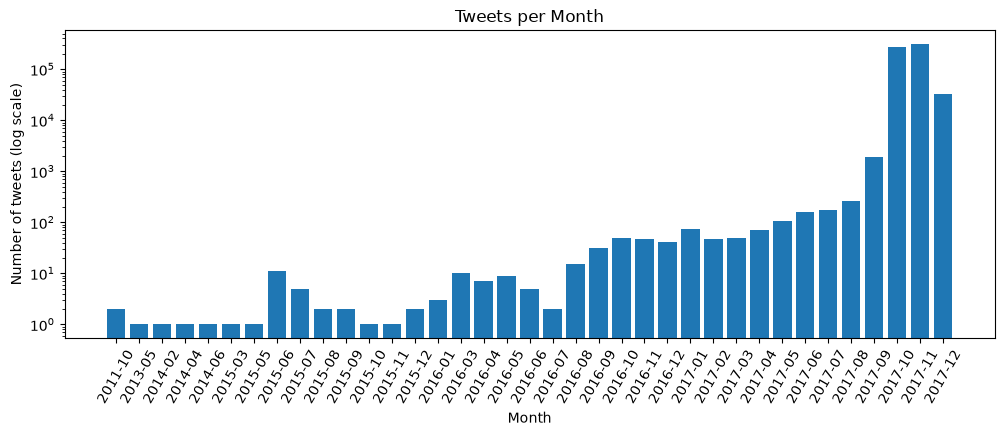

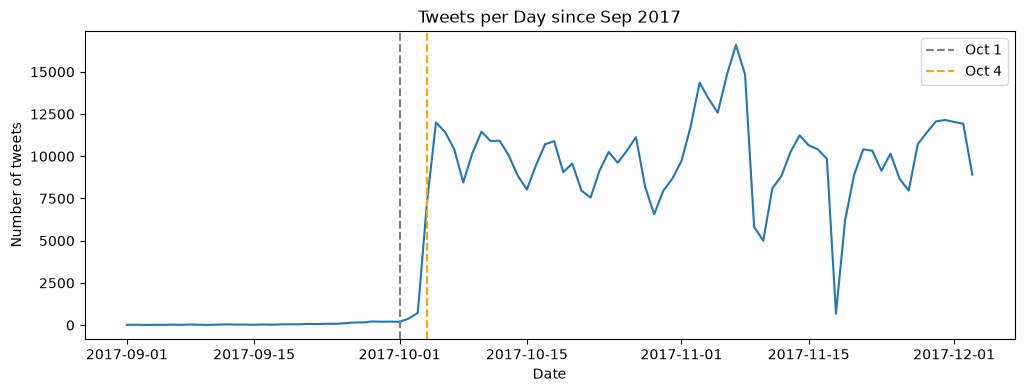

In [9]:
print("Earliest tweet:", cleaned_df["created_at"].min())
print("Latest tweet:", cleaned_df["created_at"].max())

# Count tweets per month (log scale, because early months are very small)
month_counts = pd.DataFrame({"Tweet Count": cleaned_df["created_at"].dt.strftime("%Y-%m").value_counts().sort_index()})

plt.figure(figsize=(12, 4))
plt.bar(month_counts.index, month_counts["Tweet Count"])
plt.yscale("log")
plt.xticks(rotation=60)
plt.xlabel("Month")
plt.ylabel("Number of tweets (log scale)")
plt.title("Tweets per Month")
plt.show()

# Zoom in: count tweets per day since Sep 2017
recent = cleaned_df[cleaned_df["created_at"] >= "2017-09-01"]
day_counts = recent["created_at"].dt.date.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts.values)
plt.axvline(pd.Timestamp("2017-10-01"), color="gray", linestyle="--", label="Oct 1")
plt.axvline(pd.Timestamp("2017-10-04"), color="orange", linestyle="--", label="Oct 4")
plt.xlabel("Date")
plt.ylabel("Number of tweets")
plt.title("Tweets per Day since Sep 2017")
plt.legend()
plt.show()

Most tweets are from October to early December 2017. Before that, each month has only a few tweets.

- These early tweets are scattered. They were likely pulled in because later conversations replied to them.
- The daily count jumps from a few hundred to over 6,000 on Oct 4, 2017, so continuous data collection starts there.
- We keep tweets from Oct 4, 2017 onward and remove the earlier ones.
- Both events for RQ2 come after this date: the iOS 11.1 keyboard bug (Oct 31 - Nov 9) and Black Friday / Cyber Monday (Nov 24 - Nov 27). Oct 4 - Oct 30 can serve as a normal period for comparison.

In [10]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep tweets from Oct 4, 2017
cleaned_df = cleaned_df[cleaned_df["created_at"] >= "2017-10-04"]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Earliest tweet:", cleaned_df["created_at"].min())

Tweets before filtering: 611145
Tweets after filtering: 606758
Earliest tweet: 2017-10-04 00:00:00+00:00


### 6. Detect Language

Some tweets are not in English.
Our text analysis (rude or polite words, TF-IDF, embeddings) only works for English, so we check the language of each tweet.

We use the characters in the text to guess the language:
- Hiragana or Katakana: Japanese (`japan`)
- Hangul: Korean (`korean`)
- Chinese characters: Chinese (`china`)
- Latin letters only: English or other western languages (`latin`)
- None of the above: `other`

Mentions (`@xxx`) and links are removed first, because they are always in Latin letters.

In [11]:
text = cleaned_df["text"].str.replace(r"@\w+|https?://\S+", "", regex=True)

cleaned_df["language"] = np.select(
    [text.str.contains("[\u3040-\u30ff]"),
     text.str.contains("[\uac00-\ud7af]"),
     text.str.contains("[\u4e00-\u9fff]"),
     text.str.contains("[A-Za-z]")],
    ["japan", "korean", "china", "latin"],
    default="other"
)

Tweets with the `latin` tag still include many non-English languages (Spanish, French, ...). So we use the `langdetect` package. It is slow on a large dataset, so we only run it on `latin` tweets.

We only remove non-English **customer** tweets, and keep all support tweets:
- `langdetect` sometimes labels a short English reply as another language, e.g. "Please keep us posted. ^MC".
- If the first support reply is removed, the case is lost, or a later reply is used as the first reply and the waiting time becomes too long.
- Support replies in other languages do no harm: they usually reply to non-English customer tweets, which are removed, so they are never paired into a case.

In [12]:
DetectorFactory.seed = random_seed

latin_text = text[cleaned_df["language"] == "latin"]
short = latin_text.str.split().str.len() <= 4

detected = []
for t in tqdm(latin_text[~short], desc="Detecting language"):
    try:
        detected.append(detect(t))
    except Exception:
        detected.append("unknown")

cleaned_df.loc[latin_text[short].index, "language"] = "en"
cleaned_df.loc[latin_text[~short].index, "language"] = detected

language_counts = pd.DataFrame({"Tweet Count": cleaned_df["language"].value_counts()})
language_counts.head()


Detecting language: 100%|██████████| 554279/554279 [06:06<00:00, 1512.54it/s]


,Tweet Count
language,
en,519059
japan,19982
es,19535
fr,18370
de,10318


In [13]:
print("Tweets before filtering:", cleaned_df.shape[0])
# Keep English customer tweets and all support tweets
cleaned_df = cleaned_df[(cleaned_df["language"] == "en") | (cleaned_df["inbound"] == False)]
print("Tweets after filtering:", cleaned_df.shape[0])
print("Support tweets kept without the en label:", ((cleaned_df["language"] != "en") & (cleaned_df["inbound"] == False)).sum())

Tweets before filtering: 606758
Tweets after filtering: 555973
Support tweets kept without the en label: 36914


### 7. Final Deleting

The filters above delete some tweets in the middle of a conversation. So some tweets still link to tweets that are no longer in `cleaned_df`:
- `in_response_to_tweet_id` may point to a deleted parent tweet.
- `response_tweet_id` may contain deleted reply tweets.

We do not delete these tweets, because many of them are still useful. For example, a customer tweet whose parent was deleted may still have a support reply, which we need for the response time.

So we only fix the links:
- If the parent tweet was deleted, set `in_response_to_tweet_id` to missing, and treat the tweet as the start of a conversation.
- Remove the deleted IDs from `response_tweet_id`.

In [14]:
kept_ids = set(cleaned_df["tweet_id"])

broken_parent = cleaned_df["in_response_to_tweet_id"].notna() & ~cleaned_df["in_response_to_tweet_id"].isin(kept_ids)
print("Tweets whose parent was deleted:", broken_parent.sum())
cleaned_df.loc[broken_parent, "in_response_to_tweet_id"] = pd.NA

new_responses = []
broken_replies = 0
for responses in cleaned_df["response_tweet_id"]:
    kept = [x for x in responses if x in kept_ids]
    broken_replies += len(responses) - len(kept)
    new_responses.append(kept)
cleaned_df["response_tweet_id"] = new_responses
print("Reply links pointing to deleted tweets:", broken_replies)

print("Final number of tweets:", cleaned_df.shape[0])

Tweets whose parent was deleted: 45708


Reply links pointing to deleted tweets: 39749
Final number of tweets: 555973


### 8. Save Cleaned DataFrame

In [15]:
cleaned_df.to_pickle("./data/cleaned_df.pkl")
print("Saved", cleaned_df.shape[0], "tweets to ./data/cleaned_df.pkl")

Saved 555973 tweets to ./data/cleaned_df.pkl


We only load the cleaned_df in the later task, because the language detect will cost a long time.

## Exploratory Data Analysis (RQ1)

**RQ1: Do posting time and wording affect how fast support teams respond?**

- **Section 2 - Posting time:** do tweets posted at different hours wait different amounts of time?
- **Section 3 - Wording:** do polite tweets get faster replies than rude ones?

Section 1 builds the cases used by all three research questions: each case is one customer tweet paired with the first reply from AppleSupport or AmazonHelp. We compare **medians**, because a few very long waits would pull the mean up, and we analyse the two brands separately.

### 1. Pair Customer Tweets with Replies

A case is one customer tweet paired with the first brand reply to it.

- Split the tweets into customer tweets (`inbound == True`) and support tweets (`inbound == False`).
- Match a customer tweet's `tweet_id` to a support tweet's `in_response_to_tweet_id`. Columns from the two sides get the suffixes `_customer` and `_reply`.
- Keep only pairs where the reply author is the case's brand. A few customer tweets mention both brands, and we do not want the other brand's reply.
- If a customer tweet has several replies, keep the earliest one.
- Customer tweets with no reply are left out, since they have no waiting time.
- `is_first_tweet`: `True` if the customer tweet starts a conversation, `False` if it is a follow-up inside a conversation. We keep both kinds.
- `response_minutes`: the waiting time in minutes, from the customer tweet to the first brand reply.

In [16]:
cleaned_df = pd.read_pickle("./data/cleaned_df.pkl")

# Split
customer = cleaned_df[cleaned_df["inbound"] == True]
support = cleaned_df[cleaned_df["inbound"] == False]

# Pair each customer tweet with the support replies to it
cases = customer.merge(support, left_on="tweet_id", right_on="in_response_to_tweet_id", suffixes=("_customer", "_reply"))
print("Customer-reply pairs:", cases.shape[0])

# Keep replies from the right brand, then keep only the earliest reply
cases = cases[cases["author_id_reply"] == cases["related_brand_customer"]]
cases = cases.sort_values("created_at_reply").drop_duplicates("tweet_id_customer")
# A first tweet does not reply to any other tweet
cases["is_first_tweet"] = cases["in_response_to_tweet_id_customer"].isna()
# Waiting time in minutes
cases["response_minutes"] = (cases["created_at_reply"] - cases["created_at_customer"]).dt.total_seconds() / 60
print("Cases after keeping the first brand reply:", cases.shape[0])
cases[["tweet_id_customer", "tweet_id_reply", "created_at_customer", "created_at_reply", "related_brand_customer", "is_first_tweet", "response_minutes"]].head()

Customer-reply pairs: 231529


Cases after keeping the first brand reply: 219324


,tweet_id_customer,tweet_id_reply,created_at_customer,created_at_reply,related_brand_customer,is_first_tweet,response_minutes
102158,1286995,1286994,2017-10-04 00:04:13+00:00,2017-10-04 00:12:31+00:00,AmazonHelp,False,8.300000
102157,1286993,1286992,2017-10-04 00:24:40+00:00,2017-10-04 00:33:30+00:00,AmazonHelp,False,8.833333
17297,243032,243030,2017-10-04 00:07:40+00:00,2017-10-04 00:36:31+00:00,AppleSupport,True,28.850000
32359,387506,387504,2017-10-04 00:15:29+00:00,2017-10-04 00:37:54+00:00,AppleSupport,False,22.416667
17225,242530,242529,2017-10-04 00:32:37+00:00,2017-10-04 00:58:51+00:00,AppleSupport,True,26.233333


#### Check Response Time

Cases waiting more than 24 hours: 75


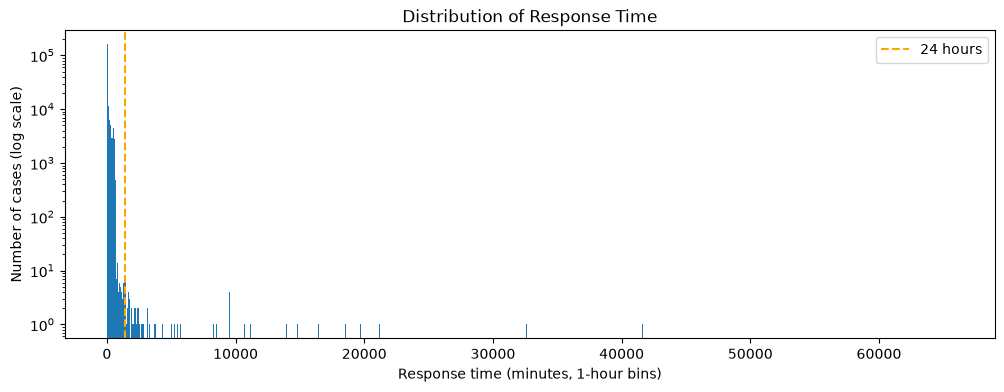

,Response Minutes
count,219324.000000
mean,79.633332
std,258.016401
min,0.766667
25%,9.050000
50%,21.483333
75%,69.150000
max,65653.433333


In [17]:
print("Cases waiting more than 24 hours:", (cases["response_minutes"] > 24 * 60).sum())

# Response time histogram with 1-hour bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, cases["response_minutes"].max() + 60, 60))
plt.axvline(24 * 60, color="orange", linestyle="--", label="24 hours")
plt.yscale("log")
plt.xlabel("Response time (minutes, 1-hour bins)")
plt.ylabel("Number of cases (log scale)")
plt.title("Distribution of Response Time")
plt.legend()
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

Most cases get a reply within a few hours. Only 75 cases wait more than 24 hours, and they are spread thinly over a long tail up to about 45 days.

- These very late replies are unlikely to be a normal first response to the customer.
- They are only about 0.03% of the cases, but they pull the mean up.
- We remove cases that wait more than 24 hours, then plot the distribution again.
- The data ends on Dec 3, 2017. A customer tweet posted in the last 24 hours before the end had less than 24 hours to get a reply, and a late reply would not be in the data. Only its fast replies are recorded, so the waiting time looks too short. We remove these cases too, so every kept case had a full 24 hours to get a reply.

Cases before removing long waits: 219324
Cases after removing long waits: 219249
Data ends at: 2017-12-03 23:13:02+00:00
Cases after removing the last 24 hours: 215852


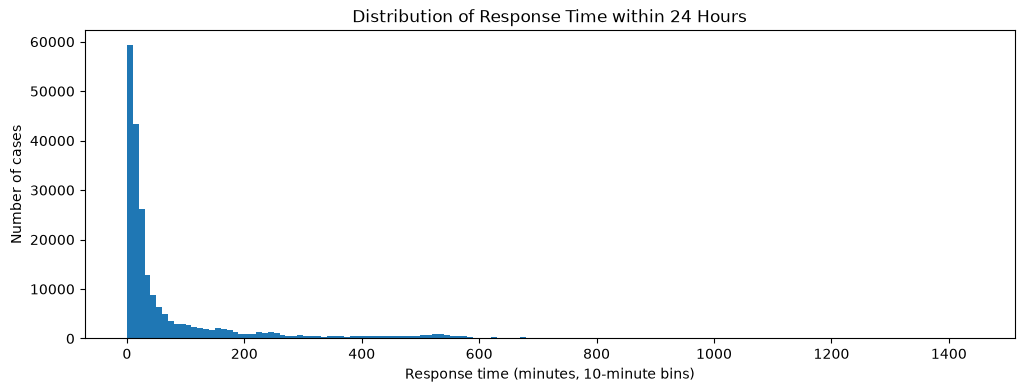

,Response Minutes
count,215852.000000
mean,77.747139
std,131.975013
min,0.766667
25%,9.150000
50%,21.683333
75%,69.900000
max,1435.466667


In [18]:
print("Cases before removing long waits:", cases.shape[0])
# Remove cases that waited more than 24 hours
cases = cases[cases["response_minutes"] <= 24 * 60].copy()
print("Cases after removing long waits:", cases.shape[0])

# Remove cases posted in the last 24 hours before the data ends
data_end = cleaned_df["created_at"].max()
minutes_to_end = (data_end - cases["created_at_customer"]).dt.total_seconds() / 60
cases = cases[minutes_to_end >= 24 * 60].copy()
print("Data ends at:", data_end)
print("Cases after removing the last 24 hours:", cases.shape[0])

# Plot again with 10-minute bins
plt.figure(figsize=(12, 4))
plt.hist(cases["response_minutes"], bins=np.arange(0, 24 * 60 + 10, 10))
plt.xlabel("Response time (minutes, 10-minute bins)")
plt.ylabel("Number of cases")
plt.title("Distribution of Response Time within 24 Hours")
plt.show()

pd.DataFrame({"Response Minutes": cases["response_minutes"].describe()})

#### Select Columns and Save

We keep the columns needed by the three research questions and give them clear names. Each row of `cases.pkl` is one case.

- `case_id`: the ID of the customer tweet. It is unique for each case.
- `brand`: the support account, `AmazonHelp` or `AppleSupport`.
- `customer_id`: the ID of the customer.
- `customer_text`: the text of the customer tweet.
- `created_at`: the time when the customer tweet was posted (UTC).
- `is_first_tweet`: whether the customer tweet starts a conversation.
- `reply_tweet_id`: the ID of the first brand reply.
- `reply_text`: the text of the first brand reply.
- `reply_at`: the time when the first brand reply was posted (UTC).
- `response_minutes`: the waiting time in minutes, from `created_at` to `reply_at`.

In [19]:
# Old column name -> new column name
new_names = {
    "tweet_id_customer": "case_id",
    "related_brand_customer": "brand",
    "author_id_customer": "customer_id",
    "text_customer": "customer_text",
    "created_at_customer": "created_at",
    "is_first_tweet": "is_first_tweet",
    "tweet_id_reply": "reply_tweet_id",
    "text_reply": "reply_text",
    "created_at_reply": "reply_at",
    "response_minutes": "response_minutes",
}
# Keep only these columns, rename them and sort by time
cases = cases[list(new_names.keys())].rename(columns=new_names)
cases = cases.sort_values("created_at").reset_index(drop=True)

# Save for RQ1, RQ2 and RQ3
cases.to_pickle("./data/cases.pkl")
print("Saved", cases.shape[0], "cases to ./data/cases.pkl")
cases.head()

Saved 215852 cases to ./data/cases.pkl


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,True,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


### 2. Effect of Posting Time

#### Local Time and Peak Events

`created_at` is stored in UTC, so we convert it to US Eastern Time (we assume most customers are in the US).

Each brand had one peak event in this period. To check that our results are not driven by these unusual days, we look at every result twice: **all days**, and **without the brand's own peak event**.

- **AppleSupport:** iOS 11.1 keyboard bug, Oct 31 - Nov 9, 2017
- **AmazonHelp:** Black Friday to Cyber Monday, Nov 24 - 27, 2017

We also group the 24 hours into four buckets: Morning (6-12), Afternoon (12-18), Evening (18-24) and Night (0-6).

In [20]:
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")
cases["hour"] = cases["local_time"].dt.hour

def time_of_day(h):
    """Map an hour (0-23) to one of four time-of-day buckets."""
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)
time_order = ["Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)", "Night (0-6)"]

# Each brand's own peak event (end date is exclusive)
events = {
    "AppleSupport": ("2017-10-31", "2017-11-10"),   # iOS 11.1 keyboard bug
    "AmazonHelp": ("2017-11-24", "2017-11-28"),     # Black Friday to Cyber Monday
}
cases["in_event"] = False
for brand, (start, end) in events.items():
    mask = (cases["brand"] == brand) & (cases["local_time"] >= start) & (cases["local_time"] < end)
    cases.loc[mask, "in_event"] = True

# The two versions of the data used in Part 1
versions = {"All days": cases, "Without peak event": cases[~cases["in_event"]]}

cases.groupby("brand")["in_event"].agg(["sum", "mean"]).round(3)

,sum,mean
brand,,
AmazonHelp,9008,0.078
AppleSupport,28446,0.285


#### Response Time by Hour

The y-axis uses a log scale so both brands fit on one chart.

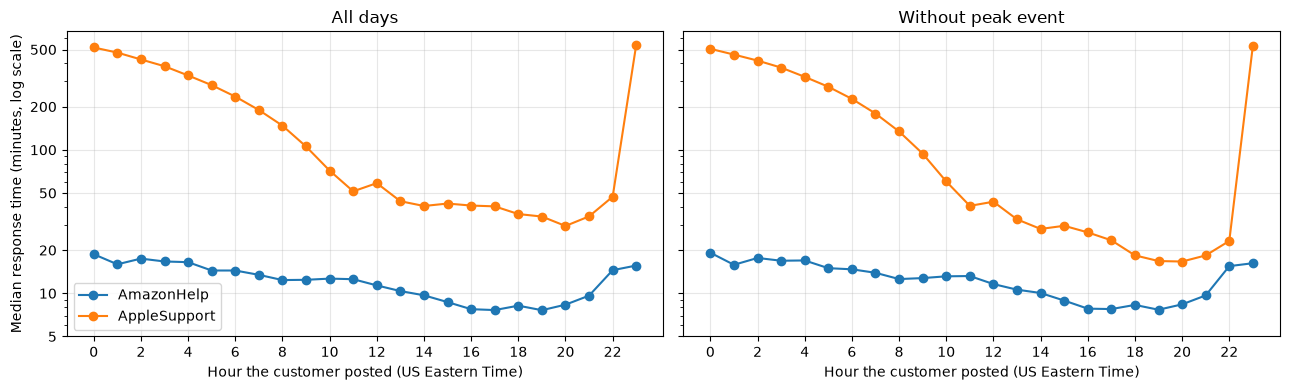

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, data) in zip(axes, versions.items()):
    hourly = data.groupby(["hour", "brand"])["response_minutes"].median().unstack()
    for brand in hourly.columns:
        ax.plot(hourly.index, hourly[brand], marker="o", label=brand)
    ax.set_yscale("log")
    ax.set_yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
    ax.set_xticks(range(0, 24, 2))
    ax.set_title(title)
    ax.set_xlabel("Hour the customer posted (US Eastern Time)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Median response time (minutes, log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

#### Response Time by Time of Day

In [22]:
# Median wait by brand and time of day, for both versions of the data
time_table = pd.concat(
    {title: data.groupby(["brand", "time_of_day"])["response_minutes"].median()
     for title, data in versions.items()},
    axis=1,
)
time_table.reindex(time_order, level="time_of_day").round(1)

All days  Without peak event
brand        time_of_day                                    
AmazonHelp   Morning (6-12)         13.0                13.4
             Afternoon (12-18)       9.3                 9.5
             Evening (18-24)        10.0                10.2
             Night (0-6)            16.4                16.7
AppleSupport Morning (6-12)        117.6                95.0
             Afternoon (12-18)      44.5                31.5
             Evening (18-24)        42.1                23.5
             Night (0-6)           438.7               417.6

#### Findings: Posting Time

- **AmazonHelp replies fast at every hour** (median 9-16 min). Night posts (0-6) wait a little longer (16.4 min) than afternoon posts (9.3 min). Removing Black Friday to Cyber Monday changes almost nothing (9.5-16.7 min): Amazon was actually slightly *faster* on those busy days, so the hourly pattern is Amazon's normal behaviour.
- **AppleSupport depends strongly on posting time.** Over all days, night posts wait 439 min (over 7 hours) vs 45 min in the afternoon, about **10 times longer**. The curve jumps at **23:00 ET** and falls slowly until about 11:00, which suggests Apple mostly stops replying late at night.
- **The iOS bug made Apple much slower during the day, but barely changed the night wait.** Without the bug period (28.5% of Apple's cases), afternoon and evening waits drop to 32 and 24 min, while night waits stay at 418 min (439 min over all days). So the night delay is not caused by the bug; without it, night posts wait about 13-18 times longer than afternoon or evening posts.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.

### 3. Effect of Words

#### Polite and Rude Words

We remove @mentions and links, then flag polite and rude tweets with **regular expressions**. The word lists were built in rounds: we started from common words, then read random unflagged tweets and added the words we had missed.

- `\b` is a word boundary, so `hate` does not match "whatever".
- `\w*` allows extra letters, so `\w*fuck\w*` matches "fucking".
- `thank(?:s|you|u)?` matches "thanks" but not "Thanksgiving".

In [23]:
# Remove @mentions and links so they don't affect word matching
text = (cases["customer_text"]
        .str.replace(r"@\w+", "", regex=True)
        .str.replace(r"http\S+", "", regex=True))

thanks_words = [r"thank(?:s|you|u)?", "thx", "ty"]
other_polite_words = [
    "please", "pls", "plz", r"appreciate\w*", "grateful", "kindly", "sorry", "excuse me",
    "could you", "would you", "regards", "dear", "hi", "hello", r"good (?:morning|afternoon|evening)",
]
rude_words = [
    r"\w*fuck\w*", r"fuk\w*", r"\w*shit\w*", r"damn\w*", r"goddam\w*", "wtf", r"crap\w*", "hell",
    "ass", r"asshole\w*", "pissed", r"screw(?:ed|s)?", "stupid", r"idiot\w*", "dumb", "ridiculous",
    "worst", "terrible", "awful", "horrible", "useless", "pathetic", "rubbish", "garbage", "trash",
    "joke", "hate", r"sucks?", "annoying", "unacceptable", "disgusting", "incompetent", "clueless",
    "lame", r"scam\w*", r"cheat\w*", r"fraud\w*", r"liars?",
]

def flag(words):
    """True for tweets containing any of the words (as whole words, any case)."""
    pattern = r"\b(?:" + "|".join(words) + r")\b"
    return text.str.contains(pattern, case=False, regex=True)

cases["has_thanks"] = flag(thanks_words)
cases["is_polite_other"] = flag(other_polite_words)
cases["is_polite"] = cases["has_thanks"] | cases["is_polite_other"]
cases["is_rude"] = flag(rude_words)

cases[["is_polite", "is_rude"]].mean().round(3)

is_polite    0.175
is_rude      0.146
dtype: float64

#### Tone Groups

A tweet can contain both polite and rude words (*"please fix this shit"*), so we put each tweet into exactly one group:

| Group | Polite words | Rude words |
|---|---|---|
| Polite | yes | no |
| Neutral | no | no |
| Mixed | yes | yes |
| Rude | no | yes |

In [24]:
cases["tone"] = np.select(
    [cases["is_polite"] & cases["is_rude"], cases["is_polite"], cases["is_rude"]],
    ["Mixed", "Polite", "Rude"],
    default="Neutral",
)
tone_order = ["Polite", "Neutral", "Mixed", "Rude"]

cases["tone"].value_counts(normalize=True).reindex(tone_order).round(3)

tone
Polite     0.157
Neutral    0.697
Mixed      0.018
Rude       0.128
Name: proportion, dtype: float64

#### Response Time by Tone

In [25]:
cases.groupby(["brand", "tone"])["response_minutes"].median().unstack().reindex(columns=tone_order).round(1)

tone,Polite,Neutral,Mixed,Rude
brand,,,,
AmazonHelp,12.5,11.6,13.3,12.8
AppleSupport,76.0,66.4,95.6,94.8


#### Is It the Wording or the Time?

Rude tweets may cluster at night or during the peak event, when the brand is slow anyway. If so, the gap above is a **time effect**, not a wording effect (time is a *confounder*). We check this for Apple, where the gap appears.

In [26]:
apple = cases[cases["brand"] == "AppleSupport"]

print("Share of rude tweets (Apple):")
print("  during the iOS bug:", round(apple.loc[apple["in_event"], "is_rude"].mean(), 3))
print("  outside the iOS bug:", round(apple.loc[~apple["in_event"], "is_rude"].mean(), 3))
print(apple.groupby("time_of_day")["is_rude"].mean().reindex(time_order).round(3))

Share of rude tweets (Apple):
  during the iOS bug: 0.25
  outside the iOS bug: 0.171
time_of_day
Morning (6-12)       0.174
Afternoon (12-18)    0.183
Evening (18-24)      0.210
Night (0-6)          0.223
Name: is_rude, dtype: float64


In [27]:
# Median wait by tone within the same time of day (Apple, outside the iOS bug)
(apple[~apple["in_event"]]
 .groupby(["time_of_day", "tone"])["response_minutes"].median()
 .unstack().reindex(index=time_order, columns=tone_order).round(1))

tone,Polite,Neutral,Mixed,Rude
time_of_day,,,,
Morning (6-12),97.8,91.5,108.3,107.1
Afternoon (12-18),30.7,31.4,32.6,33.1
Evening (18-24),24.0,22.0,35.1,30.0
Night (0-6),402.3,416.5,419.5,433.2


#### Regression: Wording Effect After Controlling for Time

A regression controls for **the exact hour and the exact date** at the same time. For each brand:

$$\log(\text{response minutes}) = \text{wording} + \text{is first tweet} + \text{hour} + \text{date}$$

- **Log** of response time: waits are very skewed, and a coefficient $b$ then means the wait changes by about $(e^b - 1) \times 100\%$.
- **Hour** and **date** are categories (`C(...)`), one adjustment per hour and per day, so busy days such as the iOS bug or Black Friday are taken into account.
- **Polite words are split** into "thanks" words and other polite words, because "thanks" is often sarcastic (*"Thanks for ruining my presents"*) and may behave differently from words such as *please*.
- `is_first_tweet` controls for whether the tweet starts a conversation ("thanks" often appears at the end of one).
- Standard errors are robust to unequal variance (HC1).

In [28]:
wording = ["is_polite_other", "has_thanks", "is_rude"]
cases["log_minutes"] = np.log(cases["response_minutes"])
cases["date"] = cases["local_time"].dt.date.astype(str)

formula = "log_minutes ~ " + " + ".join(wording) + " + is_first_tweet + C(hour) + C(date)"
models = {brand: smf.ols(formula, data=group).fit(cov_type="HC1")
          for brand, group in cases.groupby("brand")}

rows = []
for brand, model in models.items():
    median_wait = cases.loc[cases["brand"] == brand, "response_minutes"].median()
    for w in wording:
        name = w + "[T.True]"
        low, high = model.conf_int().loc[name]
        effect = np.exp(model.params[name]) - 1
        rows.append({
            "brand": brand, "feature": w,
            "effect_%": effect * 100,
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
            "approx_minutes": effect * median_wait,   # effect at the brand's median wait
        })
effects = pd.DataFrame(rows)
effects.round(3)

,brand,feature,effect_%,ci_low_%,ci_high_%,p_value,approx_minutes
0,AmazonHelp,is_polite_other,12.799,11.177,14.445,0.000,1.525
1,AmazonHelp,has_thanks,-15.304,-17.047,-13.525,0.000,-1.824
2,AmazonHelp,is_rude,4.834,3.203,6.491,0.000,0.576
3,AppleSupport,is_polite_other,0.949,-0.223,2.134,0.113,0.682
4,AppleSupport,has_thanks,-2.767,-4.311,-1.198,0.001,-1.990
5,AppleSupport,is_rude,0.307,-0.677,1.302,0.542,0.221


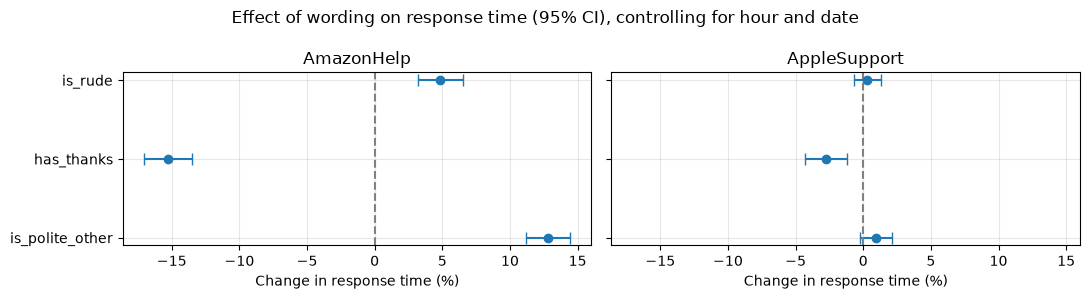

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True, sharey=True)
for ax, (brand, group) in zip(axes, effects.groupby("brand")):
    y = range(len(group))
    ax.errorbar(group["effect_%"], y, fmt="o", capsize=4,
                xerr=[group["effect_%"] - group["ci_low_%"], group["ci_high_%"] - group["effect_%"]])
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(list(y), group["feature"])
    ax.set_title(brand)
    ax.set_xlabel("Change in response time (%)")
    ax.grid(alpha=0.3)
plt.suptitle("Effect of wording on response time (95% CI), controlling for hour and date")
plt.tight_layout()
plt.show()

#### Time vs Wording: Which Matters More?

Two measures for each brand:
- **Size:** from the regression above, how much slower is the slowest posting hour than the fastest, compared with the largest wording effect?
- **R²:** how much of the variation in (log) response time does posting hour alone explain, compared with the wording features alone?

In [30]:
rows = []
for brand, model in models.items():
    group = cases[cases["brand"] == brand]
    hour_coefs = pd.Series({0: 0.0})   # hour 0 is the baseline
    for name, value in model.params.items():
        if name.startswith("C(hour)"):
            hour_coefs[int(name.split("[T.")[1].rstrip("]"))] = value
    rows.append({
        "brand": brand,
        "fastest_hour": hour_coefs.idxmin(),
        "slowest_hour": hour_coefs.idxmax(),
        "slowest_vs_fastest_hour_%": (np.exp(hour_coefs.max() - hour_coefs.min()) - 1) * 100,
        "largest_wording_effect_%": effects.loc[effects["brand"] == brand, "effect_%"].abs().max(),
        "R2_hour_only": smf.ols("log_minutes ~ C(hour)", data=group).fit().rsquared,
        "R2_wording_only": smf.ols("log_minutes ~ " + " + ".join(wording), data=group).fit().rsquared,
    })
pd.DataFrame(rows).round(3)

,brand,fastest_hour,slowest_hour,slowest_vs_fastest_hour_%,largest_wording_effect_%,R2_hour_only,R2_wording_only
0,AmazonHelp,19,0,103.156,15.304,0.053,0.006
1,AppleSupport,20,0,1666.554,2.767,0.479,0.006


#### Findings: Wording

- **How common:** 17.5% of tweets contain polite words and 14.6% rude words. In tone groups: 16% Polite, 70% Neutral, 2% Mixed, 13% Rude.
- **At first glance:** AmazonHelp waits are the same for every tone (11.6-13.3 min). AppleSupport looks slower for rude (95 min) and mixed (96 min) tweets than for neutral ones (66 min).
- **But rude tweets are posted at different times.** For Apple, 25.0% of tweets are rude during the iOS bug vs 17.1% outside it, and 22.3% at night vs 17.4% in the morning: exactly when Apple is slow anyway.
- **Within the same time of day** (outside the bug), the gap mostly disappears: in the afternoon, polite, neutral and rude tweets wait 31, 31 and 33 min.
- **The regression confirms this.** After controlling for the exact hour and date, rude wording changes Apple's wait by only +0.3% (95% CI -0.7% to +1.3%, not significant). For Amazon, rude tweets wait 4.8% longer (about half a minute).
- **Polite words have small, opposite effects for Amazon:** "thanks" tweets are answered about 15% faster (about 1.8 min), while other polite words (*please, could you, ...*) wait about 13% longer (about 1.5 min). For Apple both are small (-3% and +1%, the latter not significant). One possible reason, not tested here, is that "please" tweets often ask for something new while many "thanks" tweets close a conversation.
- **Time vs wording:** controlling for date and wording, the slowest hour (midnight) is about **2x** slower than the fastest for Amazon and about **18x** for Apple, while no wording effect is larger than 15% (Amazon) or 3% (Apple). Posting hour alone explains 5.3% (Amazon) and 48% (Apple) of the variation in log response time; wording explains 0.6% for each brand.

## RQ1 Summary

**Answer to RQ1: for both brands, *when* a customer posts matters more than *how* they write. The gap is huge for AppleSupport and moderate for AmazonHelp.**

| | Posting time | Wording (after controlling for hour and date) | R²: hour vs wording |
|---|---|---|---|
| **AmazonHelp** | Night 16.4 min vs afternoon 9.3 min; slowest hour about 2x the fastest; same without Black Friday | Small: rude +5%, "please"-type +13%, "thanks" -15% (each 2 min or less) | 5.3% vs 0.6% |
| **AppleSupport** | Night 439 min vs afternoon 45 min; slowest hour about 18x the fastest; night delay remains without the iOS bug | Tiny: rude +0.3% (not significant), "thanks" -3% | 48% vs 0.6% |

**Key points**
1. **Apple mostly stops replying late at night.** Tweets posted after about 23:00 ET wait until the next morning. This is not caused by the iOS bug. Amazon replies around the clock.
2. **Rude tweets only look slower.** They are more common at night and during the iOS bug, when Apple is slow anyway. Compared at the same hour on the same day, rude wording makes almost no difference.
3. **Polite wording has small, mixed effects for Amazon** (about 2 min either way) and almost none for Apple.
4. **For the waiting-time estimate in the Prediction step,** posting hour and date are useful inputs; wording changes the estimate by only a few minutes.

**Limitations**
- We do not know each customer's real time zone; we use US Eastern Time for everyone.
- Wording is measured only with hand-made word lists, which were not checked by hand. They cannot read sarcasm or context (e.g. sarcastic "thanks"), so some tweets are labelled wrongly, especially as polite.
- The data covers only about 9 weeks (Oct-Dec 2017), with unusual events.
- The regression shows association, not causation: tweets with different wording may also differ in ways we cannot see (e.g. harder problems).

## Influence of Peak Events (RQ2)

Analyze the effect of Planned peaks(Amazon Black Friday) and Unplanned emergency(Apple iOS Keyboard bugs), and compare.

In [1]:
import pandas as pd

df = pd.read_pickle("./data/cleaned_df.pkl")
print("Data shape:", df.shape)
df.head()

Data shape: (507873, 9)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id,related_brand,language
321,615,AmazonHelp,False,Tue Oct 31 22:29:00 +0000 2017,@115820 I'm sorry we've let you down! Without ...,[616],617,AmazonHelp,en
322,616,115820,True,Tue Oct 31 23:22:08 +0000 2017,@AmazonHelp 3 different people have given 3 di...,[618],615,AmazonHelp,en
323,618,AmazonHelp,False,Tue Oct 31 23:28:00 +0000 2017,@115820 We'd like to take a further look into ...,[619],616,AmazonHelp,en
324,619,115820,True,Tue Oct 31 23:32:26 +0000 2017,@AmazonHelp I frankly don't have the patience ...,[],618,AmazonHelp,en
325,617,115820,True,Tue Oct 31 22:16:32 +0000 2017,Way to drop the ball on customer service @1158...,[615],<NA>,AmazonHelp,en


Earliest customer message: 2017-10-04 00:03:07+00:00
Latest customer message: 2017-12-03 23:10:15+00:00


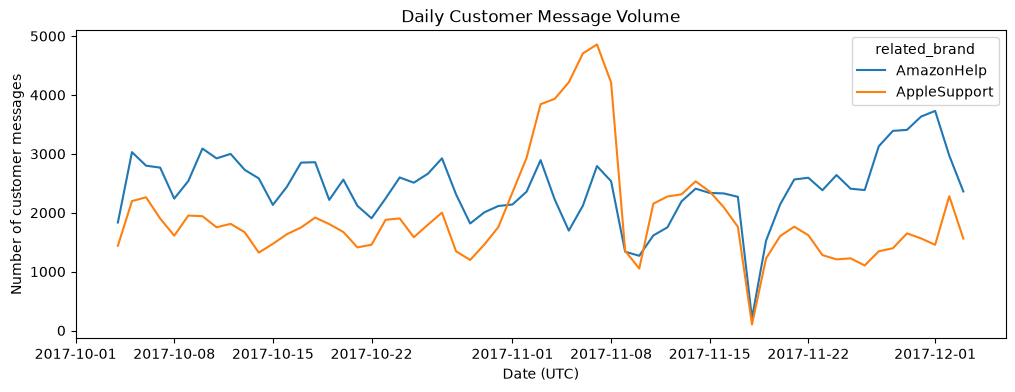

In [2]:
import matplotlib.pyplot as plt

df["created_at"] = pd.to_datetime(
    df["created_at"],
    format="%a %b %d %H:%M:%S %z %Y",
    utc=True
)

customer = df[
    (df["inbound"] == True)
    & (df["created_at"] >= "2017-10-04")
].copy()

print("Earliest customer message:", customer["created_at"].min())
print("Latest customer message:", customer["created_at"].max())

daily_counts = customer.groupby(
    [customer["created_at"].dt.date, "related_brand"]
).size().unstack(fill_value=0)

daily_counts.plot(figsize=(12, 4))
plt.xlabel("Date (UTC)")
plt.ylabel("Number of customer messages")
plt.title("Daily Customer Message Volume")
plt.show()

In [3]:
daily_counts.loc[
    pd.Timestamp("2017-11-15").date():
    pd.Timestamp("2017-11-29").date()
]

related_brand,AmazonHelp,AppleSupport
created_at,,
2017-11-15,2336,2360
2017-11-16,2328,2092
2017-11-17,2270,1760
2017-11-18,209,102
2017-11-19,1526,1224
2017-11-20,2142,1604
2017-11-21,2565,1763
2017-11-22,2594,1618
2017-11-23,2382,1281


In [4]:
nov18 = df[
    (df["created_at"] >= "2017-11-18")
    & (df["created_at"] < "2017-11-19")
]

hourly_counts = nov18.groupby(
    [nov18["created_at"].dt.hour, "related_brand"]
).size().unstack(fill_value=0)

hourly_counts = hourly_counts.reindex(range(24), fill_value=0)
hourly_counts.index.name = "Hour (UTC)"
hourly_counts

related_brand,AmazonHelp,AppleSupport
Hour (UTC),,
0,13,10
1,14,5
2,14,8
3,10,1
4,6,3
5,8,3
6,16,2
7,27,2
8,19,2


In [5]:
nearby = df[
    (df["created_at"] >= "2017-11-17")
    & (df["created_at"] < "2017-11-20")
]

message_counts = nearby.groupby(
    [
        nearby["created_at"].dt.date,
        "related_brand",
        "inbound"
    ]
).size().unstack(fill_value=0)

message_counts = message_counts.rename(
    columns={False: "Support messages", True: "Customer messages"}
)

message_counts

inbound                   Support messages  Customer messages
created_at related_brand                                     
2017-11-17 AmazonHelp                 1940               2270
           AppleSupport               1672               1760
2017-11-18 AmazonHelp                  184                209
           AppleSupport                 78                102
2017-11-19 AmazonHelp                 1267               1526
           AppleSupport               1135               1224

### Data Coverage Check

Both customer and support message counts are unusually low on
November 18, 2017, for AmazonHelp and AppleSupport.

The cause cannot be confirmed from the cleaned data alone.
We flag this date and will compare results with and without it
if it falls within a comparison period.

In [6]:
support = df[df["inbound"] == False][
    ["tweet_id", "author_id", "in_response_to_tweet_id", "created_at"]
].copy()

support = support.rename(columns={
    "tweet_id": "reply_id",
    "author_id": "reply_brand",
    "in_response_to_tweet_id": "customer_tweet_id",
    "created_at": "reply_at"
})

pairs = customer.merge(
    support,
    left_on=["tweet_id", "related_brand"],
    right_on=["customer_tweet_id", "reply_brand"],
    how="inner"
)

pairs = pairs[pairs["reply_at"] >= pairs["created_at"]]
first_replies = pairs.sort_values("reply_at").drop_duplicates("tweet_id")

cases = customer.merge(
    first_replies[["tweet_id", "reply_id", "reply_at"]],
    on="tweet_id",
    how="left"
)

cases["response_minutes"] = (
    cases["reply_at"] - cases["created_at"]
).dt.total_seconds() / 60

print("Customer messages:", len(cases))
print("Messages with a recorded reply:", cases["reply_at"].notna().sum())
print("Messages without a recorded reply:", cases["reply_at"].isna().sum())

cases[
    ["tweet_id", "related_brand", "created_at", "reply_at", "response_minutes"]
].head()

Customer messages: 266767
Messages with a recorded reply: 209938
Messages without a recorded reply: 56829


,tweet_id,related_brand,created_at,reply_at,response_minutes
0,616,AmazonHelp,2017-10-31 23:22:08+00:00,2017-10-31 23:28:00+00:00,5.866667
1,619,AmazonHelp,2017-10-31 23:32:26+00:00,NaT,NaN
2,617,AmazonHelp,2017-10-31 22:16:32+00:00,2017-10-31 22:29:00+00:00,12.466667
3,621,AmazonHelp,2017-10-31 22:19:34+00:00,2017-10-31 22:28:34+00:00,9.000000
4,627,AmazonHelp,2017-11-01 12:50:18+00:00,2017-11-01 12:53:34+00:00,3.266667


In [7]:
response_summary = cases.groupby(
    "related_brand"
)["response_minutes"].describe(
    percentiles=[0.5, 0.9, 0.99]
)

response_summary

,count,mean,std,min,50%,90%,99%,max
related_brand,,,,,,,,
AmazonHelp,111568.0,21.842175,295.016025,0.766667,12.033333,33.321667,124.322000,65653.433333
AppleSupport,98370.0,147.899596,197.154102,1.200000,72.000000,449.750000,623.705167,21181.933333


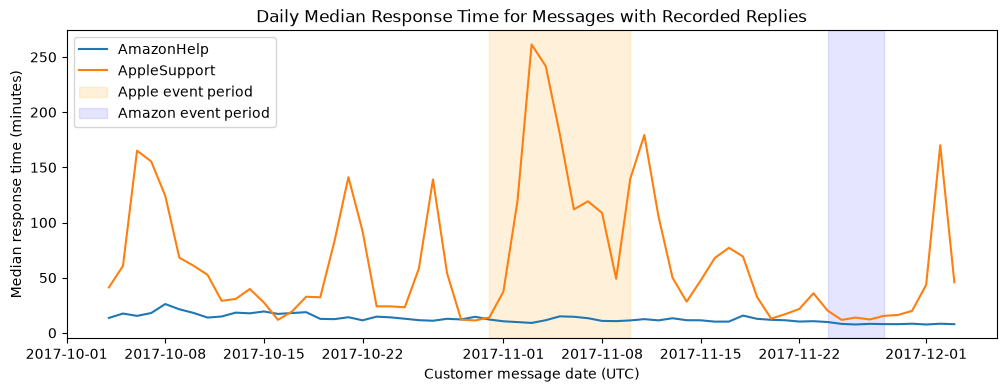

In [8]:
daily_response = cases.groupby(
    [cases["created_at"].dt.date, "related_brand"]
)["response_minutes"].median().unstack()

daily_response.plot(figsize=(12, 4))

plt.axvspan(
    pd.Timestamp("2017-10-31"),
    pd.Timestamp("2017-11-10"),
    color="orange",
    alpha=0.15,
    label="Apple event period"
)

plt.axvspan(
    pd.Timestamp("2017-11-24"),
    pd.Timestamp("2017-11-28"),
    color="blue",
    alpha=0.1,
    label="Amazon event period"
)

plt.xlabel("Customer message date (UTC)")
plt.ylabel("Median response time (minutes)")
plt.title("Daily Median Response Time for Messages with Recorded Replies")
plt.legend()
plt.show()

In [9]:
cases["period"] = "Other"

apple = cases["related_brand"] == "AppleSupport"
amazon = cases["related_brand"] == "AmazonHelp"

cases.loc[
    apple
    & (cases["created_at"] >= "2017-10-17")
    & (cases["created_at"] < "2017-10-31"),
    "period"
] = "Baseline"

cases.loc[
    apple
    & (cases["created_at"] >= "2017-10-31")
    & (cases["created_at"] < "2017-11-10"),
    "period"
] = "Event"

cases.loc[
    amazon
    & (cases["created_at"] >= "2017-11-10")
    & (cases["created_at"] < "2017-11-24"),
    "period"
] = "Baseline"

cases.loc[
    amazon
    & (cases["created_at"] >= "2017-11-24")
    & (cases["created_at"] < "2017-11-28"),
    "period"
] = "Event"

comparison = cases[cases["period"] != "Other"].copy()

summary = comparison.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    recorded_replies=("response_minutes", "count"),
    median_minutes=("response_minutes", "median")
)

summary["p90_minutes"] = comparison.groupby(
    ["related_brand", "period"]
)["response_minutes"].quantile(0.9)

summary.round(2)

customer_messages  recorded_replies  median_minutes  \
related_brand period                                                          
AmazonHelp    Baseline              27589             21417           11.30   
              Event                 10562              8149            8.43   
AppleSupport  Baseline              23182             18862           47.38   
              Event                 34152             27492          154.68   

                        p90_minutes  
related_brand period                 
AmazonHelp    Baseline        31.25  
              Event           28.22  
AppleSupport  Baseline       401.88  
              Event          536.35

In [10]:
comparison["reply_within_24h"] = (
    comparison["response_minutes"] <= 24 * 60
)

summary["period_days"] = [14, 4, 14, 10]

summary["messages_per_day"] = (
    summary["customer_messages"] / summary["period_days"]
)

summary["reply_within_24h_rate"] = comparison.groupby(
    ["related_brand", "period"]
)["reply_within_24h"].mean()

summary[
    [
        "messages_per_day",
        "median_minutes",
        "p90_minutes",
        "reply_within_24h_rate"
    ]
].round(3)

messages_per_day  median_minutes  p90_minutes  \
related_brand period                                                    
AmazonHelp    Baseline          1970.643          11.300       31.250   
              Event               2640.5           8.433       28.220   
AppleSupport  Baseline          1655.857          47.383      401.878   
              Event               3415.2         154.675      536.348   

                        reply_within_24h_rate  
related_brand period                           
AmazonHelp    Baseline                  0.776  
              Event                     0.771  
AppleSupport  Baseline                  0.813  
              Event                     0.805

In [11]:
without_nov18 = comparison[
    comparison["created_at"].dt.date
    != pd.Timestamp("2017-11-18").date()
].copy()

sensitivity = without_nov18.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    median_minutes=("response_minutes", "median"),
    reply_within_24h_rate=("reply_within_24h", "mean")
)

sensitivity["period_days"] = summary["period_days"].copy()
sensitivity.loc[("AmazonHelp", "Baseline"), "period_days"] = 13

sensitivity["messages_per_day"] = (
    sensitivity["customer_messages"] / sensitivity["period_days"]
)

sensitivity[
    ["messages_per_day", "median_minutes", "reply_within_24h_rate"]
].round(3)

messages_per_day  median_minutes  \
related_brand period                                       
AmazonHelp    Baseline          2106.154          11.267   
              Event               2640.5           8.433   
AppleSupport  Baseline          1655.857          47.383   
              Event               3415.2         154.675   

                        reply_within_24h_rate  
related_brand period                           
AmazonHelp    Baseline                  0.775  
              Event                     0.771  
AppleSupport  Baseline                  0.813  
              Event                     0.805

In [12]:
first_messages = comparison[
    comparison["in_response_to_tweet_id"].isna()
].copy()

first_summary = first_messages.groupby(
    ["related_brand", "period"]
).agg(
    customer_messages=("tweet_id", "size"),
    recorded_replies=("response_minutes", "count"),
    median_minutes=("response_minutes", "median"),
    reply_within_24h_rate=("reply_within_24h", "mean")
)

first_summary["p90_minutes"] = first_messages.groupby(
    ["related_brand", "period"]
)["response_minutes"].quantile(0.9)

first_summary.round(3)

customer_messages  recorded_replies  median_minutes  \
related_brand period                                                          
AmazonHelp    Baseline              11909             11271          10.867   
              Event                  4622              4422           8.000   
AppleSupport  Baseline              14173             13340          57.592   
              Event                 23469             21350         159.600   

                        reply_within_24h_rate  p90_minutes  
related_brand period                                        
AmazonHelp    Baseline                  0.946       31.250  
              Event                     0.957       28.017  
AppleSupport  Baseline                  0.941      419.330  
              Event                     0.909      539.218

### Check Using Conversation-Starting Messages

We repeat the comparison using customer messages with no recorded
parent tweet ID.

- Amazon's median response time decreases from 10.87 to 8.00 minutes.
  Its recorded 24-hour reply rate increases from about 94.6% to 95.7%.
- Apple's median response time increases from 57.59 to 159.60 minutes.
  Its recorded 24-hour reply rate decreases from about 94.1% to 90.9%.
- The direction of the response-time changes is consistent with
  the analysis using all customer messages.
- These results describe two company-event cases. Company differences
  and issue types may also contribute to the observed changes.

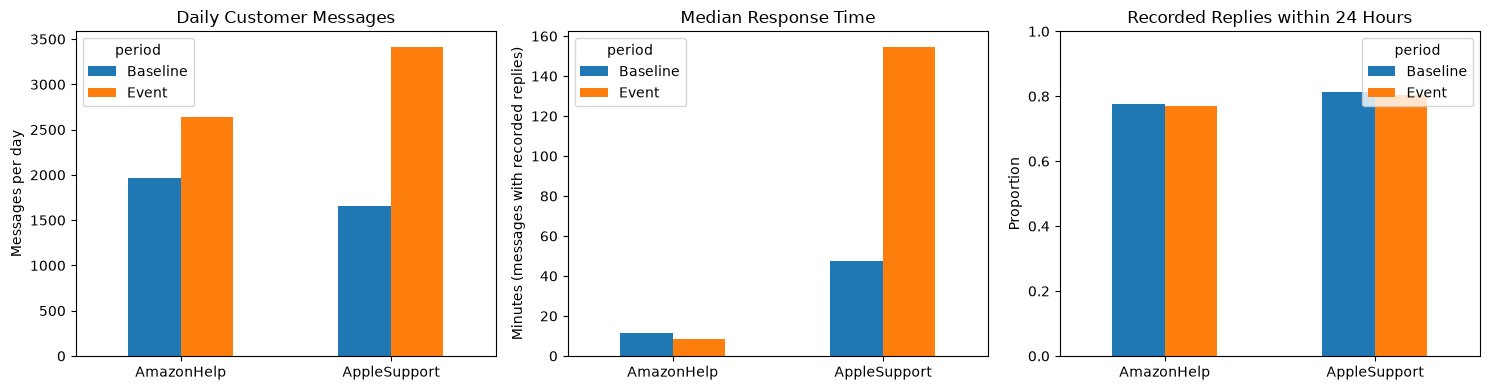

In [13]:
metrics = [
    "messages_per_day",
    "median_minutes",
    "reply_within_24h_rate"
]

titles = [
    "Daily Customer Messages",
    "Median Response Time",
    "Recorded Replies within 24 Hours"
]

ylabels = [
    "Messages per day",
    "Minutes (messages with recorded replies)",
    "Proportion"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric, title, ylabel in zip(axes, metrics, titles, ylabels):
    values = summary[metric].unstack("period")
    values = values[["Baseline", "Event"]]
    values.plot.bar(ax=ax, rot=0)

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)

axes[2].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### RQ2 Findings

- Amazon's daily customer message count increased from about 1,971
  to 2,641 during Black Friday–Cyber Monday. Among messages with
  recorded replies, the median response time decreased from 11.30
  to 8.43 minutes. The recorded 24-hour reply rate remained close
  to 77%.

- Apple's daily customer message count increased from about 1,656
  to 3,415 during the proposed iOS keyboard-bug period. Among messages
  with recorded replies, the median response time increased from
  47.38 to 154.68 minutes. The recorded 24-hour reply rate decreased
  from about 81.3% to 80.5%.

- Excluding November 18, an unusually low-volume date, preserved
  the direction of Amazon's results. The message-volume increase
  became about 25.4%.

- Restricting the analysis to conversation-starting messages also
  preserved the direction of the response-time changes. Amazon's
  recorded 24-hour reply rate increased, while Apple's decreased.

### Interpretation and Limitations

Amazon maintained faster recorded responses during its planned
shopping event, while Apple experienced longer waits during the
unexpected issue period.

These comparisons describe two company-event cases. Differences
in staffing, issue complexity, and the size of the demand increase
may also explain the results.

The analysis includes all messages associated with each brand.
Individual messages have not been verified as related to the
shopping events or keyboard bug.

Reply rates describe direct replies recorded in this dataset.
Data collection and cleaning may affect which replies are available.
The baseline and event periods also have different weekday mixes.

## Retrieving Related Cases (RQ3)

Recommendation System, compare two retrieval methods:
- TF-IDF
- Vector cosine similarity

### 1. Read Data

Load the cases from `cleaning2.ipynb` and all tweets from `cleaned_df.pkl`.

RQ3: customer asks a new question -> find similar past cases -> show how support handled them.

A new question is the start of a conversation, so we only keep conversation starts in the library. Tweets like "still waiting" mean nothing without context. They still show up later, when we print the whole conversation of a case.

Every case is a customer tweet. We keep it if:
- `is_first_tweet == True`: it does not reply to another tweet (conversation start).
- It is also the customer's earliest tweet in the data. Some customers follow up by sending a new tweet, not a reply, e.g. "Just to be clear.. I have been home ALL day!". This is a conversation start but not a new question.

Cases that pass both are called first questions below.

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [35]:
# Load the cases and all tweets
# tweets are used to find each customer's earliest tweet and full conversations
cases = pd.read_pickle("./data/cases.pkl")
tweets = pd.read_pickle("./data/cleaned_df.pkl")

# Turn the time text into UTC datetime
tweets["created_at"] = pd.to_datetime(tweets["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)
print("All cases:", cases.shape[0])

# Keep conversation starts: customer tweets that do not reply to another tweet
cases = cases[cases["is_first_tweet"]].copy()
print("Conversation starts (customer tweets that are not replies):", cases.shape[0])

All cases: 209868
Conversation starts (customer tweets that are not replies): 127617


First questions (also the customer's earliest tweet): 110816


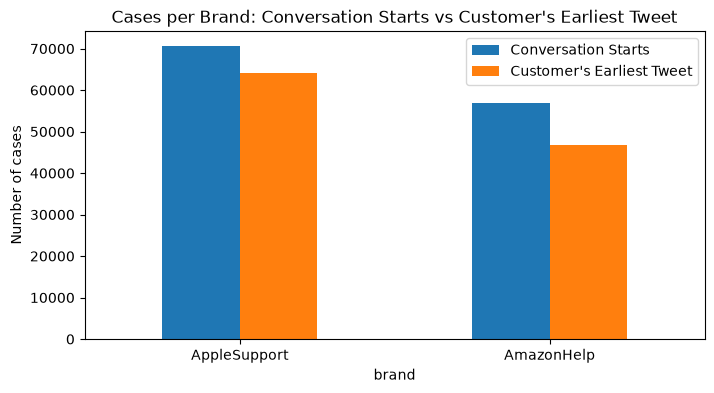

,Conversation Starts,Customer's Earliest Tweet
brand,,
AppleSupport,70701,64031
AmazonHelp,56916,46785


In [36]:
before = cases["brand"].value_counts()
# Find each customer's earliest tweet time, keep the case only if it is that tweet
customer_first_time = tweets[tweets["inbound"] == True].groupby("author_id")["created_at"].min()
cases = cases[cases["created_at"] == cases["customer_id"].map(customer_first_time)].copy()
print("First questions (also the customer's earliest tweet):", cases.shape[0])

# Compare the number of cases per brand before and after
brand_counts = pd.DataFrame({"Conversation Starts": before, "Customer's Earliest Tweet": cases["brand"].value_counts()})
brand_counts.plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylabel("Number of cases")
plt.title("Cases per Brand: Conversation Starts vs Customer's Earliest Tweet")
plt.show()
brand_counts

### 2. Clean Text

New column `clean_text` is used for retrieval. `customer_text` is kept for display.

- `html.unescape` turns HTML entities back into symbols, like `&amp;` -> `&`. In this data only `&amp;`, `&lt;`, `&gt;` appear.
- Remove `@` mentions and links, they do not describe the problem.
- Lowercase, join extra spaces.
- Punctuation, stop words and emojis are kept, since the embedding model works better on full sentences.

Texts with 3 words or fewer (like "fix this") are removed. They do not tell what the problem is.

In [37]:
import html

# Turn HTML entities into symbols
cases["clean_text"] = cases["customer_text"].apply(html.unescape)

# Remove @ mentions and links
cases["clean_text"] = cases["clean_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)

# Lowercase and join extra spaces
cases["clean_text"] = cases["clean_text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
cases[["customer_text", "clean_text"]].head()

,customer_text,clean_text
2,Apple Podcast is not played continuously on #iOS11 Is there a solution to this problem? @AppleSupport,apple podcast is not played continuously on #ios11 is there a solution to this problem?
5,@AppleSupport since I updated to the most current update the bar which shows how much you’ve listened to doesn’t move https://t.co/VUYr3hkWo0,since i updated to the most current update the bar which shows how much you’ve listened to doesn’t move
6,"@AppleSupport my iPhone used to work fine with my BMW iDrive. After ios11, it won’t work (music and texts)! Please help!","my iphone used to work fine with my bmw idrive. after ios11, it won’t work (music and texts)! please help!"
7,@AppleSupport will there be a fix for the poor #batterylife after update #iOS11 my phone has to be charged several times a day after #SE,will there be a fix for the poor #batterylife after update #ios11 my phone has to be charged several times a day after #se
8,@AppleSupport song previews aren’t playing on ITunes Store on my computer or iPhone. They just buffer forever and nothing happens.,song previews aren’t playing on itunes store on my computer or iphone. they just buffer forever and nothing happens.


In [38]:
# Count words and remove texts with 3 words or fewer
cases["word_count"] = cases["clean_text"].str.split().str.len()
print("Cases before removing short texts:", cases.shape[0])
cases = cases[cases["word_count"] > 3].copy()
print("Cases after removing short texts:", cases.shape[0])

Cases before removing short texts: 110816
Cases after removing short texts: 110022


### 3. Split Data

Split by time: past cases -> answer new questions.

- `history`: before Nov 27, 2017. The library we search in.
- `query`: Nov 27 to Dec 3, 2017 (last 7 days). The new questions.

A query cannot find itself in the library. The history set covers the iOS bug and Black Friday periods. Nov 27 is Cyber Monday, so the query set has a few more Amazon tweets.

We only search within the same brand as the query.

In [39]:
# The last 7 days are new questions (query), the rest is the library (history)
cases["set"] = np.where(cases["created_at"] >= "2017-11-27", "query", "history")
pd.DataFrame({"Number of Cases": cases.groupby(["set", "brand"]).size()})

Number of Cases
set     brand                        
history AmazonHelp              39162
        AppleSupport            58169
query   AmazonHelp               7372
        AppleSupport             5319

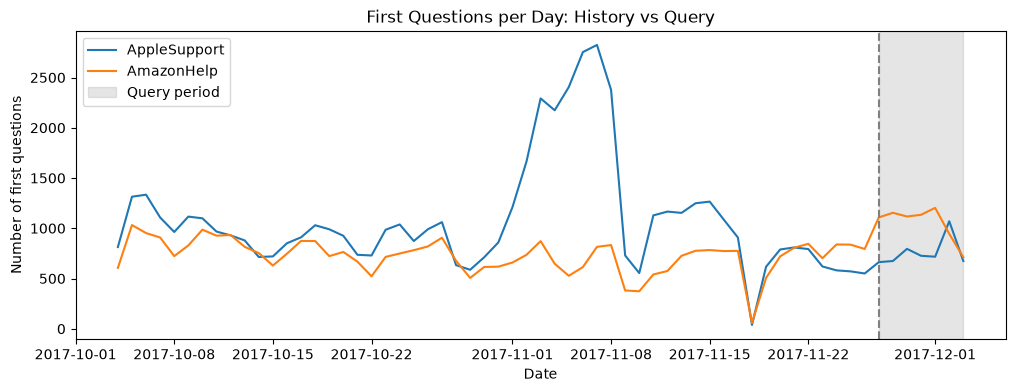

In [65]:
# First questions per day for each brand, with the query period shaded
day_counts = cases.groupby([cases["created_at"].dt.date, "brand"]).size().unstack()
plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts["AppleSupport"], label="AppleSupport")
plt.plot(day_counts.index, day_counts["AmazonHelp"], label="AmazonHelp")
plt.axvline(pd.Timestamp("2017-11-27"), color="gray", linestyle="--")
plt.axvspan(pd.Timestamp("2017-11-27"), pd.Timestamp("2017-12-03"), color="gray", alpha=0.2, label="Query period")
plt.xlabel("Date")
plt.ylabel("Number of first questions")
plt.title("First Questions per Day: History vs Query")
plt.legend()
plt.show()

### 4. Method A: TF-IDF

TF-IDF turns a tweet into a vector of word weights. A word gets more weight if it is in this tweet but rare in the history set. So words like "battery" or "refund" matter more than common words.

- Fit on the history set only, then transform the queries.
- `stop_words="english"`: drop words like "the", "my".
- `min_df=2`: drop words that appear only once (typos, order numbers).
- The vectors have length 1, so the product of two vectors is the cosine similarity.

First look at the top 5 matches of one example query and their conversations, then the best-match score of 1,000 sample queries.

`get_chain(case_id)`: start from the first tweet -> keep adding tweets that reply to the chain -> sort by time. Used again in Section 5.

In [41]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Split into history and query
history = cases[cases["set"] == "history"].reset_index(drop=True)
query = cases[cases["set"] == "query"].reset_index(drop=True)
# Fit TF-IDF on history only, then transform the queries
tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_tfidf = tfidf.fit_transform(history["clean_text"])
query_tfidf = tfidf.transform(query["clean_text"])
print("Vocabulary size:", len(tfidf.vocabulary_))
print("History matrix:", history_tfidf.shape)
print("Query matrix:", query_tfidf.shape)

Vocabulary size: 14450
History matrix: (97331, 14450)
Query matrix: (12691, 14450)


In [42]:
pd.set_option("display.max_colwidth", None)
# Pick one example query
example = query.sample(1, random_state=1007).index[0]
print("Brand:", query.loc[example, "brand"])
print("Query:", query.loc[example, "customer_text"])

# Cosine similarity with every history case; other brand gets -1 so it is never picked
scores = (history_tfidf @ query_tfidf[example].T).toarray().ravel()
scores[(history["brand"] != query.loc[example, "brand"]).to_numpy()] = -1
# Index of the 5 highest scores
top = np.argsort(scores)[::-1][:5]
pd.DataFrame({"Score": scores[top], "Case ID": history.loc[top, "case_id"], "History Tweet": history.loc[top, "customer_text"]})

Brand: AmazonHelp
Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
84918,0.321978,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
45833,0.317164,2606680,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
39690,0.306331,1279910,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
90183,0.301404,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
60593,0.288863,1640913,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"


In [43]:
# Collect a case and all tweets that reply to it (directly or later in the chain)
def get_chain(case_id):
    chain_ids = [case_id]
    while True:
        new_ids = tweets.loc[tweets["in_response_to_tweet_id"].isin(chain_ids) & ~tweets["tweet_id"].isin(chain_ids), "tweet_id"].tolist()
        if len(new_ids) == 0:
            break
        chain_ids = chain_ids + new_ids
    # Sort the conversation by time
    chain = tweets[tweets["tweet_id"].isin(chain_ids)].sort_values("created_at")
    return pd.DataFrame({"Time": chain["created_at"].dt.strftime("%Y-%m-%d %H:%M"), "Author": np.where(chain["inbound"], "Customer", chain["author_id"]), "Text": chain["text"]})

# Show the full conversation of each top-5 match
for rank, i in enumerate(top):
    print(f"Match {rank + 1}, score {scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.322


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 2, score 0.317


,Time,Author,Text
2437477,2017-10-30 21:00,Customer,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
2437471,2017-10-30 21:04,AmazonHelp,@737428 I'm sorry for the poor delivery experiences! Have we missed a recent delivery for an order you placed? ^ME
2437472,2017-10-30 21:07,Customer,"@AmazonHelp A day late on delivery, about to be 2. No up to date tracking info. No package. I'm wondering why you continue to use this courrier"
2437473,2017-10-30 21:25,AmazonHelp,"@737428 If you have a moment, please contact us directly by phone or chat so we can look into this with you: https://t.co/Q7Ftz6nj80 ^LH"
2437474,2017-10-30 21:48,Customer,@AmazonHelp I spoke to someone on the phone. I was given a promo code but it still doesn't really fix the underlying problem with Intelcom itself.
2437475,2017-10-30 23:36,AmazonHelp,@737428 I understand the frustration with a late order! Did the agent mention sending your feedback to our transportation team? ^TN
2437476,2017-10-30 23:39,Customer,@AmazonHelp Yeah she did. Whether or not they'll actually do anything with the complaint is anyone's guess.


Match 3, score 0.306


,Time,Author,Text
1158697,2017-10-26 16:37,Customer,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
1158696,2017-10-26 16:45,AmazonHelp,@419470 I'm sorry to hear we've let you down! Have we missed the delivery date shown in confirmation e-mail? What is the status? ^FR


Match 4, score 0.301


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.289


,Time,Author,Text
1494601,2017-11-05 23:24,Customer,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"
1494599,2017-11-05 23:55,AmazonHelp,@501652 I'm sorry to hear this! Are you currently waiting on the delivery of a late package? ^BH
1494600,2017-11-06 00:00,Customer,"@AmazonHelp Item showing as delivered and was refunded already. But this is the 4th/5th time that Intelcom has ""delivered"" an item that never arrived"


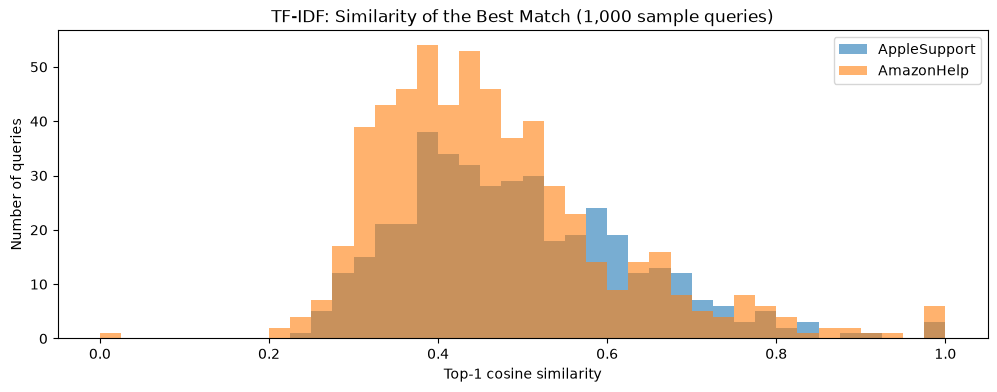

,count,mean,std,min,25%,50%,75%,max
brand,,,,,,,,
AmazonHelp,584.0,0.467082,0.141206,0.000000,0.367797,0.441375,0.530206,1.0
AppleSupport,416.0,0.496510,0.139874,0.229057,0.394541,0.476872,0.580237,1.0


In [44]:
# For 1,000 sample queries, record the best score within the same brand
sample = query.sample(1000, random_state=1007)
top1 = []
for i in sample.index:
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    top1.append(scores[(history["brand"] == query.loc[i, "brand"]).to_numpy()].max())
sample["tfidf_top1"] = top1

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("TF-IDF: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()
sample.groupby("brand")["tfidf_top1"].describe()

### 5. Method B: Embedding

An embedding model turns a tweet into a vector of its meaning, not only its words. "package never arrived" and "didn't receive my order" share no words, so TF-IDF cannot link them, but their embeddings are close.

- Model: `all-MiniLM-L6-v2` (sentence-transformers), 384 numbers for each tweet.
- Input is the same `clean_text` as TF-IDF, to keep the comparison fair.
- Encoding takes a few minutes on CPU, so the vectors are saved in `./data/*.npy`. Delete these files if the steps above change.

Similarity is computed with NumPy:
- Normalize: divide each vector by its length (`np.linalg.norm`). The product of two length-1 vectors is the cosine similarity. The model output already has length 1, the check below confirms it.
- One query: `history_emb @ query_vector` gives the scores of all history cases.
- Many queries: one matrix product for each brand, then `.max(axis=1)` to get the best score of each query. No loop over queries.

Same example query and same 1,000 sample queries as Section 4. The scores of the two methods are not on the same scale, so they are not compared here. See Section 6.

In [45]:
import os
import time
from sentence_transformers import SentenceTransformer

# Encode once and save; later runs load the saved arrays
if os.path.exists("./data/history_emb.npy") and os.path.exists("./data/query_emb.npy"):
    history_emb = np.load("./data/history_emb.npy")
    query_emb = np.load("./data/query_emb.npy")
else:
    model = SentenceTransformer("all-MiniLM-L6-v2")
    start = time.time()
    history_emb = model.encode(history["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    query_emb = model.encode(query["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    print(f"Encoding time: {time.time() - start:.0f} seconds")
    np.save("./data/history_emb.npy", history_emb)
    np.save("./data/query_emb.npy", query_emb)

# Check the saved arrays still match the current data
print("Rows match history and query:", history_emb.shape[0] == len(history) and query_emb.shape[0] == len(query))

Rows match history and query: True


In [46]:
# Length of each vector (one number per row)
history_norm = np.linalg.norm(history_emb, axis=1, keepdims=True)
query_norm = np.linalg.norm(query_emb, axis=1, keepdims=True)
print("Vector lengths before normalizing (first 5):", history_norm[:5].ravel().round(3))

# Divide each row by its own length (broadcasting), so every vector has length 1
history_emb = history_emb / history_norm
query_emb = query_emb / query_norm
print("All lengths are 1:", np.allclose(np.linalg.norm(history_emb, axis=1), 1) and np.allclose(np.linalg.norm(query_emb, axis=1), 1))
print("History embeddings:", history_emb.shape, history_emb.dtype, f"{history_emb.nbytes / 1e6:.0f} MB")
print("Query embeddings:", query_emb.shape, query_emb.dtype, f"{query_emb.nbytes / 1e6:.0f} MB")

Vector lengths before normalizing (first 5): [1. 1. 1. 1. 1.]
All lengths are 1: True
History embeddings: (97331, 384) float32 150 MB
Query embeddings: (12691, 384) float32 19 MB


In [47]:
# Same example query as Section 4: dot product with every history vector
print("Query:", query.loc[example, "customer_text"])
emb_scores = history_emb @ query_emb[example]

# Other brand gets -1 so it is never picked, then take the 5 highest scores
same_brand = (history["brand"] == query.loc[example, "brand"]).to_numpy()
emb_scores[~same_brand] = -1
emb_top = np.argsort(emb_scores)[::-1][:5]
pd.DataFrame({"Score": emb_scores[emb_top], "Case ID": history.loc[emb_top, "case_id"], "History Tweet": history.loc[emb_top, "customer_text"]})

Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
88692,0.798062,2753577,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
71973,0.790825,2205311,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
84918,0.719627,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
90183,0.675058,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
89921,0.668758,2792004,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!


In [48]:
# Show the full conversation of each top-5 match
for rank, i in enumerate(emb_top):
    print(f"Match {rank + 1}, score {emb_scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.798


,Time,Author,Text
2582429,2017-11-21 01:43,Customer,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
2582427,2017-11-21 01:47,AmazonHelp,"@770774 I'm very sorry you haven't received your order. Whenever you have the time, give us a shout here: https://t.co/Q7Ftz6ETZy We'd be happy to assist with your order in real-time. ^SK"
2582428,2017-11-21 01:59,Customer,"@AmazonHelp I've been in contact with you guys twice already. You guys have been as helpful as you can be, it's the courier that you use that isn't. You cannot get a hold of them and their tracking system doesn't work."


Match 2, score 0.791


,Time,Author,Text
2046618,2017-11-09 22:41,Customer,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
2046617,2017-11-09 22:44,AmazonHelp,"@644809 I'm so sorry to hear this, Ash! We like our customers to have a great experience with us, and it seems we've let you down! Without posting personal account information, tell us more about your situation.\n-Anita"


Match 3, score 0.720


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 4, score 0.675


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.669


,Time,Author,Text
2619689,2017-11-21 20:30,Customer,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!
2619688,2017-11-21 20:37,AmazonHelp,@779217 I'm sorry for the late package! We'd love to help! Let's take a look into this further in real-time. When you can please reach out to us through phone or chat here: https://t.co/JzP7hlA23B


AppleSupport similarity table: (416, 58169)
AmazonHelp similarity table: (584, 39162)
Time for 1,000 queries: 0.10 seconds


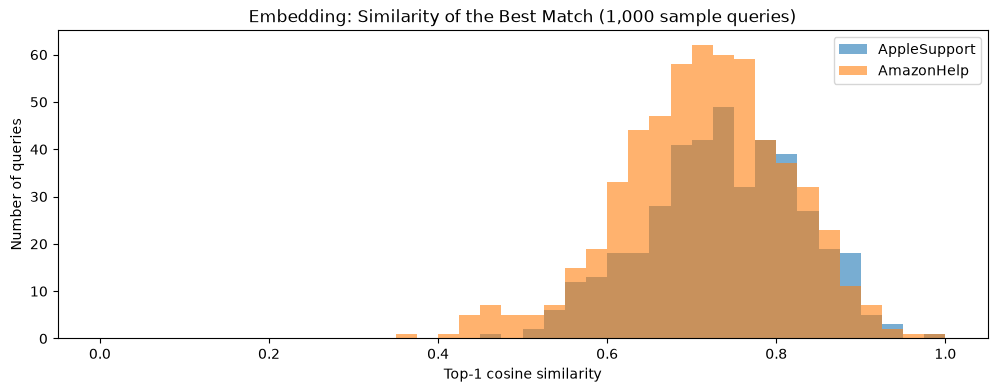

,25th Percentile,Median,75th Percentile
AppleSupport,0.681069,0.737897,0.804021
AmazonHelp,0.652070,0.719193,0.779103


In [49]:
# Same 1,000 sample queries as Section 4; one matrix product per brand instead of a loop over queries
start = time.time()
sample["emb_top1"] = 0.0
for brand in ["AppleSupport", "AmazonHelp"]:
    rows = (sample["brand"] == brand).to_numpy()
    brand_history = history_emb[(history["brand"] == brand).to_numpy()]
    sim = query_emb[sample.index[rows]] @ brand_history.T
    print(brand, "similarity table:", sim.shape)
    sample.loc[rows, "emb_top1"] = sim.max(axis=1)
print(f"Time for 1,000 queries: {time.time() - start:.2f} seconds")

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("Embedding: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()

# Median and quartiles of the best score with NumPy
brands = ["AppleSupport", "AmazonHelp"]
pd.DataFrame({
    "25th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 25) for b in brands],
    "Median": [np.median(sample.loc[sample["brand"] == b, "emb_top1"]) for b in brands],
    "75th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 75) for b in brands],
}, index=brands)

### 6. Evaluate

No label in the data says which cases are similar, so accuracy cannot be computed directly. We compare the two methods in indirect ways, with the same 1,000 sample queries.

#### 6.1 How Different Are the Results?

If the two methods return the same top 5, there is nothing to compare. So first count how many cases are in both top-5 lists for each query. 0: completely different. 5: identical.

In [50]:
# Top-5 history cases for each sample query: one row per query, one column per rank
k = 5
tfidf_top5 = np.zeros((len(sample), k), dtype=int)
emb_top5 = np.zeros((len(sample), k), dtype=int)

# TF-IDF: one query at a time
for n, i in enumerate(sample.index):
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    scores[(history["brand"] != query.loc[i, "brand"]).to_numpy()] = -1
    tfidf_top5[n] = np.argsort(scores)[::-1][:k]

# Embedding: one matrix product per brand, then sort each row from high to low
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    sim = query_emb[sample.index[rows]] @ history_emb[brand_index].T
    emb_top5[rows] = brand_index[np.argsort(sim, axis=1)[:, ::-1][:, :k]]

print("TF-IDF top-5 table:", tfidf_top5.shape)
print("Embedding top-5 table:", emb_top5.shape)

TF-IDF top-5 table: (1000, 5)
Embedding top-5 table: (1000, 5)


Average number of shared cases: 0.505


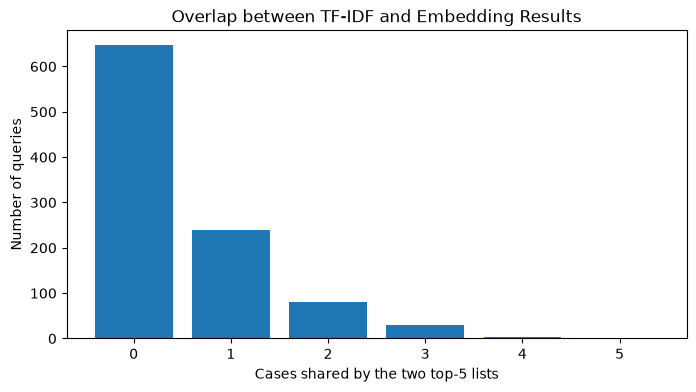

,Shared Cases,Number of Queries
0,0,647
1,1,239
2,2,81
3,3,29
4,4,3
5,5,1


In [51]:
# Count the cases that appear in both top-5 lists of each query
shared = np.array([len(np.intersect1d(tfidf_top5[n], emb_top5[n])) for n in range(len(sample))])
shared_counts = np.bincount(shared, minlength=k + 1)
print("Average number of shared cases:", shared.mean())

plt.figure(figsize=(8, 4))
plt.bar(np.arange(k + 1), shared_counts)
plt.xlabel("Cases shared by the two top-5 lists")
plt.ylabel("Number of queries")
plt.title("Overlap between TF-IDF and Embedding Results")
plt.show()
pd.DataFrame({"Shared Cases": np.arange(k + 1), "Number of Queries": shared_counts})

#### 6.2 Reply Similarity

Idea: similar problem -> similar reply from support. So we compare the real reply of a query with the replies of its top-5 matches. Higher similarity means better matches.

Two problems:
- Template replies like "send us a dm" make any two cases look similar. So a random baseline is added: 5 random cases from the same brand. A useful method should be clearly higher than random.
- The judge may be biased. Using embeddings to score replies may favor the embedding method, and using TF-IDF may favor TF-IDF. So both are used as judges. If a method wins under both judges, the result is more reliable.

Steps: clean replies (mentions, links, signatures like `^KH`) -> score with each judge -> mean over the 5 matches -> mean over the 1,000 queries.

For the embedding judge, only the replies we need are encoded (about 12,000). `np.searchsorted` and broadcasting compute the 1,000 x 5 similarities at once.

In [52]:
# Clean reply text: remove mentions, links and agent signatures like ^KH
history["reply_clean"] = history["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
history["reply_clean"] = history["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
sample["reply_clean"] = sample["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
sample["reply_clean"] = sample["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

# How common are template replies?
print("History replies whose exact text is used more than once:", history["reply_clean"].duplicated(keep=False).sum(), "of", len(history))
pd.DataFrame({"Count": history["reply_clean"].value_counts().head(5)})

History replies whose exact text is used more than once: 19281 of 97331


,Count
reply_clean,
here’s what you can do to work around the issue until it’s fixed in a future software update:,4861
thanks for reaching out. we have a workaround for this here: dm us if you still need help.,575
thanks for reaching out. we're here to help. dm us so we can look into this further with you.,280
we're here to help. let's take this to dm so we can better assist you.,224
let's look into that. send us a dm and we'll go from there.,204


In [53]:
# Random baseline: 5 random history cases from the same brand for each query
rng = np.random.default_rng(1007)
random_top5 = np.zeros((len(sample), k), dtype=int)
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    random_top5[rows] = rng.choice(brand_index, size=(rows.sum(), k))
methods = {"Random": random_top5, "TF-IDF": tfidf_top5, "Embedding": emb_top5}

# Judge 1: TF-IDF similarity between the query's real reply and the replies of its 5 matches
reply_tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_reply_tfidf = reply_tfidf.fit_transform(history["reply_clean"])
sample_reply_tfidf = reply_tfidf.transform(sample["reply_clean"])
tfidf_judge = {}
for name, top5 in methods.items():
    tfidf_judge[name] = np.array([(history_reply_tfidf[top5[n]] @ sample_reply_tfidf[n].T).toarray().mean() for n in range(len(sample))])
    print("TF-IDF judge,", name, "mean reply similarity:", tfidf_judge[name].mean().round(3))

TF-IDF judge, Random mean reply similarity: 0.043
TF-IDF judge, TF-IDF mean reply similarity: 0.08
TF-IDF judge, Embedding mean reply similarity: 0.093


In [54]:
# Judge 2: embedding similarity; encode only the history replies that some method picked
needed = np.unique(np.concatenate([random_top5, tfidf_top5, emb_top5]))
model = SentenceTransformer("all-MiniLM-L6-v2")
needed_reply_emb = model.encode(history.loc[needed, "reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
sample_reply_emb = model.encode(sample["reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
needed_reply_emb = needed_reply_emb / np.linalg.norm(needed_reply_emb, axis=1, keepdims=True)
sample_reply_emb = sample_reply_emb / np.linalg.norm(sample_reply_emb, axis=1, keepdims=True)
print("Encoded history replies:", needed_reply_emb.shape)

emb_judge = {}
for name, top5 in methods.items():
    # Position of each matched case in the needed array, then a (1000, 5, 384) block of reply vectors
    matched = needed_reply_emb[np.searchsorted(needed, top5)]
    # Broadcasting: multiply each query reply with its 5 matched replies and sum over the 384 numbers
    sim = (matched * sample_reply_emb[:, np.newaxis, :]).sum(axis=2)
    emb_judge[name] = sim.mean(axis=1)
    print("Embedding judge,", name, "mean reply similarity:", emb_judge[name].mean().round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/49 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Encoded history replies: (12539, 384)
Embedding judge, Random mean reply similarity: 0.293
Embedding judge, TF-IDF mean reply similarity: 0.369
Embedding judge, Embedding mean reply similarity: 0.398


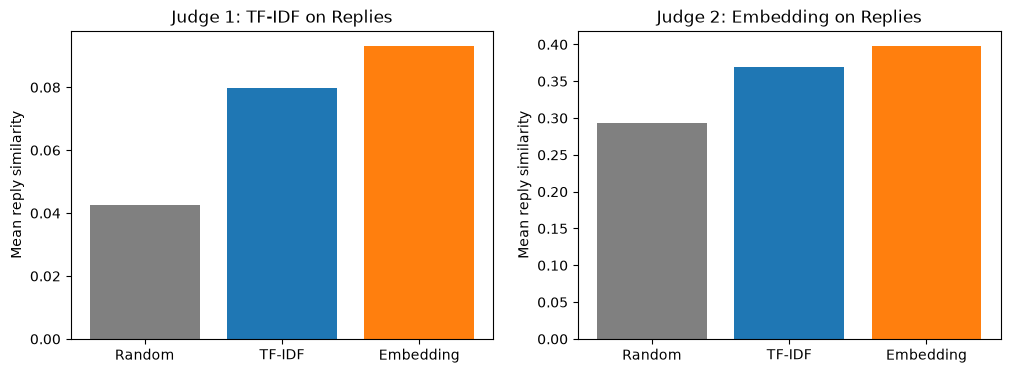

TF-IDF judge: Embedding wins 554 queries, TF-IDF wins 428 queries
Embedding judge: Embedding wins 600 queries, TF-IDF wins 399 queries


,TF-IDF Judge,Embedding Judge
Random,0.042543,0.293174
TF-IDF,0.079886,0.368697
Embedding,0.093247,0.398386


In [55]:
# Mean reply similarity of each method under each judge
summary = pd.DataFrame({
    "TF-IDF Judge": [tfidf_judge[name].mean() for name in methods],
    "Embedding Judge": [emb_judge[name].mean() for name in methods],
}, index=list(methods.keys()))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(summary.index, summary["TF-IDF Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 1: TF-IDF on Replies")
plt.subplot(1, 2, 2)
plt.bar(summary.index, summary["Embedding Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 2: Embedding on Replies")
plt.show()

# Query by query: how often does one method beat the other?
print("TF-IDF judge: Embedding wins", (tfidf_judge["Embedding"] > tfidf_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (tfidf_judge["TF-IDF"] > tfidf_judge["Embedding"]).sum(), "queries")
print("Embedding judge: Embedding wins", (emb_judge["Embedding"] > emb_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (emb_judge["TF-IDF"] > emb_judge["Embedding"]).sum(), "queries")
summary

#### 6.3 Example Queries

The numbers in 6.2 are averages, so here we look at single queries.

- gap = reply similarity of embedding - reply similarity of TF-IDF (embedding judge). gap > 0: embedding did better on this query.
- The histogram shows the gap of all 1,000 queries.
- Then read the two queries with the largest gap in each direction, with the top 3 matches of both methods and their replies.

Mean gap: 0.03
Queries with a gap between -0.1 and 0.1: 657 of 1000


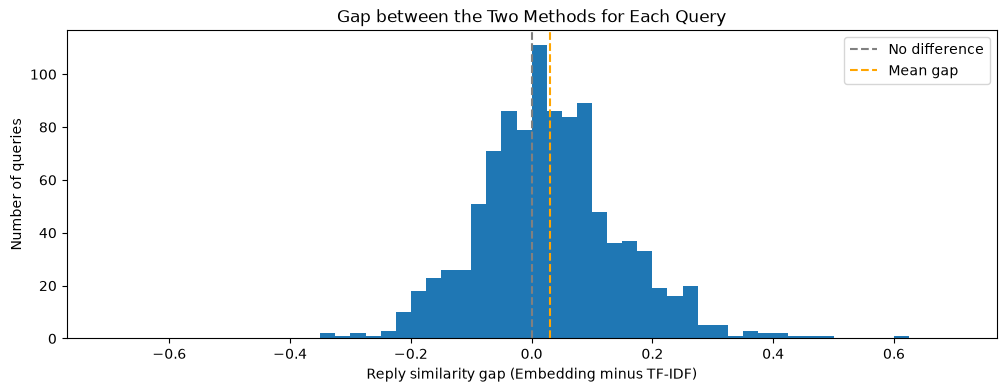

In [56]:
# Gap of each query: positive means the embedding method did better than TF-IDF
gap = emb_judge["Embedding"] - emb_judge["TF-IDF"]
print("Mean gap:", gap.mean().round(3))
print("Queries with a gap between -0.1 and 0.1:", ((gap > -0.1) & (gap < 0.1)).sum(), "of", len(gap))

plt.figure(figsize=(12, 4))
plt.hist(gap, bins=np.linspace(-0.7, 0.7, 57))
plt.axvline(0, color="gray", linestyle="--", label="No difference")
plt.axvline(gap.mean(), color="orange", linestyle="--", label="Mean gap")
plt.xlabel("Reply similarity gap (Embedding minus TF-IDF)")
plt.ylabel("Number of queries")
plt.title("Gap between the Two Methods for Each Query")
plt.legend()
plt.show()

In [57]:
# The two queries with the largest gap in each direction
examples = {"Embedding wins by the most": np.argmax(gap), "TF-IDF wins by the most": np.argmin(gap)}

for title, n in examples.items():
    print(f"{title} (gap {gap[n]:.3f})")
    print("Query:", sample.iloc[n]["customer_text"])
    print("Real reply:", sample.iloc[n]["reply_text"])
    # Top-3 matches of each method and the support reply each one got
    top3 = np.concatenate([tfidf_top5[n, :3], emb_top5[n, :3]])
    display(pd.DataFrame({"Method": ["TF-IDF"] * 3 + ["Embedding"] * 3, "Rank": [1, 2, 3] * 2, "History Tweet": history.loc[top3, "customer_text"].to_numpy(), "Reply": history.loc[top3, "reply_text"].to_numpy()}))

Embedding wins by the most (gap 0.624)
Query: @115850  when shall the next  Great Indian Sale begin??  Very much excited to shop  from this brilliant online shopping site.  Hoping to get more offers and discounts next time.
Real reply: @620757 We haven't made an announcement yet. Please stay tuned to our website. ^KA


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,Amazon India is the worst shopping online site,@443827 That's quite a comment. Please let us know what went wrong so that we can look into it? ^BV
1,TF-IDF,2,"@115850 \nHi, is the cashback of Great indian Sale being delayed for everyone or just me?",@211368 We'd like to know more about this. Could you help us with the offer name/cash back page link? We'll look into it. ^HD
2,TF-IDF,3,Thanks @115850 for Great Indian Festival 🎆 🎇... HapPy shopping...,"@196039 Aww thank you, we appreciate the kind words and we're here to help if you need us :) ^VN"
3,Embedding,1,"Hello, what are the upcoming sales in November on Amazon India?",@688861 We haven't made any announcements yet. Stay tuned to Amazon.in where we highlight the latest offers. ^AS
4,Embedding,2,@AmazonHelp When will be the amazon black Friday sale in india??Any updates...,"@416535 We haven't announced any dates as of now, kindly stay tuned to our website for updates. ^RD"
5,Embedding,3,When #amazon festive #sale starting in india? #eagerly #AmazonIndia @AmazonHelp,@294042 We have not made any announcement on this yet. Please stay tuned. ^HK


TF-IDF wins by the most (gap -0.336)
Query: @AppleSupport  I'm having issues with iPhone 7, running 11.1.2. it has developed a bug where every 2mins the screen go black and a spinning wheel appear, after that it goes to the lock screen and wants my passcode. i've changed the date to 30Nov as a temp fix and it works.
Real reply: @245932 You're in the right place for help. Let’s make sure you have a backup, then follow the steps in this article, which includes updating to iOS version 11.2: https://t.co/Wc5MHFZb0p

If you have any questions, let us know.


,Method,Rank,History Tweet,Reply
0,TF-IDF,1,My sound working when it wants and when I’m on the phone my screen is black not to my lock screen @115858 FIX IT,@496180 DM us using the link below and let us know your iOS version from Settings &gt; General &gt; About &gt; Version. We're glad to assist. https://t.co/GDrqU22YpT
1,TF-IDF,2,"This new iOS 11 bug sucks. Log in to phone and see this spinning wheel, goes back to lock screen, then have to log in again to get it to work. Using PIN; not FaceID. @AppleSupport https://t.co/nUkPxw19Gp",@303338 We’re here to help. Please DM us the version of iOS 11 you’re using so we can better assist you. https://t.co/GDrqU22YpT
2,TF-IDF,3,@AppleSupport why do I keep getting this spinning wheel screen and then back to PIN unlock screen. Happens multiple times a day. 11.1.2. iPhone 7+ https://t.co/CJrwMfjpAx,"@279191 Thank you for reaching out. May we ask when you started to notice this? Was it after a recent iOS update? Also, have you noticed this more with certain apps DM us and let us know. https://t.co/GDrqU22YpT"
3,Embedding,1,"@AppleSupport why do I intermittently get a black screen w/ a spinning wheel after unlocking w/ passcode on #iphonex ? It happened w/fresh iPhone, I’ve restarted, latest iOS, still happening w/ reloaded backup. https://t.co/NU4oGzKnpj","@668391 We want your iPhone X to be working perfectly! Meet us in DM, tell us which country you're in, and we'll take a look there. https://t.co/GDrqU22YpT"
4,Embedding,2,@AppleSupport why do I keep getting this spinning wheel screen and then back to PIN unlock screen. Happens multiple times a day. 11.1.2. iPhone 7+ https://t.co/CJrwMfjpAx,"@279191 Thank you for reaching out. May we ask when you started to notice this? Was it after a recent iOS update? Also, have you noticed this more with certain apps DM us and let us know. https://t.co/GDrqU22YpT"
5,Embedding,3,"@AppleSupport Hi, have a weird issue with iPhone 7 running iOS 11.0.2. Can I DM you with the details?",@193307 Absolutely. Let us know what's going on in DM. https://t.co/GDrqU22YpT


#### 6.4 Summary

Results on the 1,000 sample queries:

- The two methods return different cases. On average only 0.5 of the 5 matches are shared, and 647 queries share nothing.
- Both are better than random under both judges. TF-IDF judge: random 0.043, TF-IDF 0.080, embedding 0.093. Embedding judge: 0.293, 0.369, 0.398.
- Embedding is a little better. It is higher under both judges and wins more queries (554 vs 428, 600 vs 399).
- But the difference is small. The mean gap is 0.03, and 657 queries have a gap between -0.1 and 0.1.

The two examples:

- Embedding wins: the customer asks when the next sale begins. TF-IDF matches tweets with the same words ("shopping", "Great Indian"), but they are a complaint, a cashback question and a thank-you. Embedding finds the same question asked in other words, and the replies are almost the same as the real reply.
- TF-IDF wins: a spinning wheel and lock screen bug. Both methods find the same problem and even share one match. TF-IDF only wins because the wording of the replies is closer. So winning on one query does not always mean better matches.

Limits:

- Reply similarity is an indirect measure. The same problem can get replies in different words, and about 20% of the history replies are reused templates.
- Only 1,000 queries from one week are tested.
- The matches are not checked by hand yet.

We use the embedding method in the prediction part. TF-IDF is kept as a baseline: no model to download, and it is good at rare names like "Intelcom".

### 7. Search Function for Prediction

Put the embedding method into one function for `prediction.ipynb`.

User input -> clean -> encode -> similar cases of the same brand.

- Library: the last week was kept out only for the evaluation. In real use it is also history, so history and query are stacked together with `pd.concat` (tables) and `np.vstack` (vectors).
- Saved files: `./data/search_cases.pkl` (cases) and `./data/search_emb.npy` (vectors). Rows are in the same order.
- `search(text, brand, k=5)`: returns the `k` most similar cases with score, case ID, customer tweet, first reply and waiting minutes.
- `get_chain(case_id)`: shows the full conversation of a match.

Tested with two made-up questions. The last plot shows the waiting time of the 20 most similar cases. How to turn it into a predicted waiting time is left to the prediction part.

In [58]:
# The evaluation is done, so the last week joins the library: stack tables and vectors in the same order
search_cases = pd.concat([history, query], ignore_index=True)
search_emb = np.vstack([history_emb, query_emb])
print("Library cases:", search_cases.shape[0])
print("Library embeddings:", search_emb.shape)
print("Rows match:", search_cases.shape[0] == search_emb.shape[0])

# Keep the columns needed for search and save both files for prediction.ipynb
search_cases = search_cases[["case_id", "brand", "customer_text", "reply_text", "created_at", "response_minutes"]]
search_cases.to_pickle("./data/search_cases.pkl")
np.save("./data/search_emb.npy", search_emb)

Library cases: 110022
Library embeddings: (110022, 384)
Rows match: True


In [59]:
def search(text, brand, k=5):
    # Clean the new question with the same rules as Section 2
    clean = pd.Series([html.unescape(text)])
    clean = clean.str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)
    clean = clean.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    # Encode it and make the vector length 1
    vector = model.encode(clean.tolist())[0]
    vector = vector / np.linalg.norm(vector)
    # Cosine similarity with every library case; other brand gets -1 so it is never picked
    scores = search_emb @ vector
    scores[(search_cases["brand"] != brand).to_numpy()] = -1
    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({
        "Score": scores[top],
        "Case ID": search_cases.loc[top, "case_id"].to_numpy(),
        "Customer Tweet": search_cases.loc[top, "customer_text"].to_numpy(),
        "First Reply": search_cases.loc[top, "reply_text"].to_numpy(),
        "Response Minutes": search_cases.loc[top, "response_minutes"].to_numpy(),
    })

In [60]:
# Try two made-up new questions, one for each brand
new_questions = [
    ("My package says delivered but I never received it", "AmazonHelp"),
    ("Battery drains very fast after updating to iOS 11", "AppleSupport"),
]
for text, brand in new_questions:
    print("New question:", text, f"({brand})")
    result = search(text, brand)
    display(result)
    print("Full conversation of the best match:")
    display(get_chain(result.loc[0, "Case ID"]))

New question: My package says delivered but I never received it (AmazonHelp)


,Score,Case ID,Customer Tweet,First Reply,Response Minutes
0,0.861001,1112103,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH",10.133333
1,0.847082,842259,I never received my @115821 order and it says it was delivered yesterday @AmazonHelp,@320336 Sorry to hear you didn't receive your package! We would love to help. Let's try the steps here: https://t.co/X8TflYmLFV ^SH,44.150000
2,0.838711,2948178,@115821 Its says my package was delivered but it hasnt been,"@814234 I'm sorry you don't have your package, Hero! Please give these steps a try: https://t.co/GmDjuh55FG, and keep us updated on the outcome. ^WJ",6.383333
3,0.832715,1189461,Did not received my package @115850.,@399598 Could you please confirm if we have missed the mentioned time frame? 2/2 ^AH,17.800000
4,0.826213,2888208,@115821 I never received my package :/ says it was delivered. What do I do?,"@800865 I'm sorry for the trouble with delivery, Chloe! Have you tried these steps in regard to finding your package: https://t.co/7LYbk5TtST? Let us know! ^TG",12.050000


Full conversation of the best match:


,Time,Author,Text
1003609,2017-10-24 02:08,Customer,Sos @115821 @AmazonHelp @118706 @123967 my package says delivered but it never got here https://t.co/U4aRe8cPbG
1003606,2017-10-24 02:18,AmazonHelp,"@382462 Just in case, have you checked your mailbox? Please also try these steps and keep us posted: https://t.co/8W0piplqfc ^BH"
1003607,2017-10-24 02:19,Customer,@AmazonHelp I did check my mailbox and my neighbors porch just Incase it got delivered to the wrong house
1003608,2017-10-24 02:40,AmazonHelp,"@382462 Sorry you didn't get your package. Sometimes carriers accidentally scan early. If you don't see it by tomorrow, let us know!^EB"


New question: Battery drains very fast after updating to iOS 11 (AppleSupport)


,Score,Case ID,Customer Tweet,First Reply,Response Minutes
0,0.907320,2025149,@115858 @AppleSupport my battery is draining faster than ever on the new iOS 11.0 https://t.co/A72Hv7hsyQ,@598901 Let's see what we can find out! You’ll want to start by backing up and updating to iOS 11.1. DM us if the issue persists. https://t.co/GDrqU22YpT,294.066667
1,0.898212,2059764,"@AppleSupport Battery drains faster even after updating to iOS 11.0.2, needs a fix especially for the battery draining issue.",@609180 We know how vital the battery is. Please check out this article: https://t.co/TpjqFp3jxD \n\nDM us the results. https://t.co/GDrqU22YpT,522.083333
2,0.897160,2029103,@AppleSupport my battery is draining faster than ever on the new iOS 11.1,"@600050 That's not how we want an update to behave! Meet us in DM, tell us which country you're in and we'll take a look. https://t.co/GDrqU22YpT",179.333333
3,0.895723,1975916,facing faster battery drain issues after upgrading to ios 11.1 @AppleSupport @115858,"@585138 Hey there, we'd be happy to look into this with you. DM us and let us know which device this is happening on. We'll go from there. https://t.co/GDrqU22YpT",45.433333
4,0.895549,1097746,@AppleSupport what is the fix for the fast battery drain since I upgraded to IOS 11.0.3?,@379044 We'd love to help you with your iPhone battery. DM us and we'll continue there. https://t.co/GDrqU2kzhr,6.166667


Full conversation of the best match:


,Time,Author,Text
1868930,2017-11-06 11:05,Customer,@115858 @AppleSupport my battery is draining faster than ever on the new iOS 11.0 https://t.co/A72Hv7hsyQ
1868929,2017-11-06 15:59,AppleSupport,@598901 Let's see what we can find out! You’ll want to start by backing up and updating to iOS 11.1. DM us if the issue persists. https://t.co/GDrqU22YpT


Median waiting time of the 20 similar cases: 114.2 minutes
Median waiting time of all AppleSupport cases: 89.3 minutes


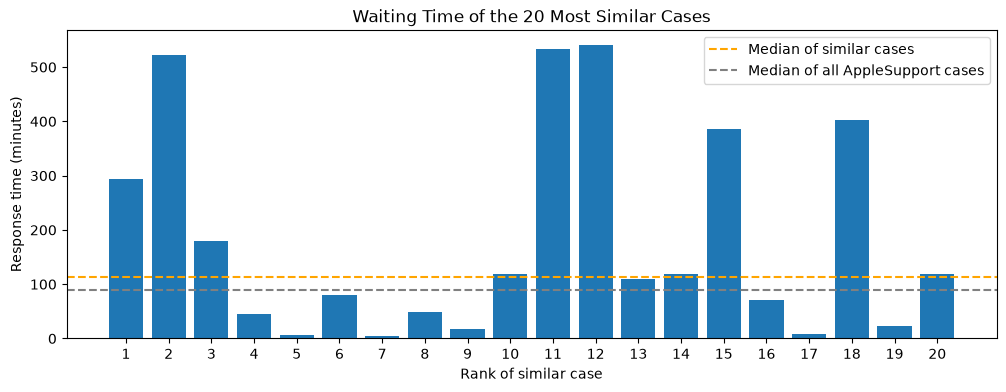

In [61]:
# Waiting time of the 20 most similar cases, compared with the median of all cases of the brand
similar = search("Battery drains very fast after updating to iOS 11", "AppleSupport", k=20)
brand_median = np.median(search_cases.loc[search_cases["brand"] == "AppleSupport", "response_minutes"])
similar_median = np.median(similar["Response Minutes"])
print("Median waiting time of the 20 similar cases:", similar_median.round(1), "minutes")
print("Median waiting time of all AppleSupport cases:", brand_median.round(1), "minutes")

plt.figure(figsize=(12, 4))
plt.bar(np.arange(1, 21), similar["Response Minutes"])
plt.axhline(similar_median, color="orange", linestyle="--", label="Median of similar cases")
plt.axhline(brand_median, color="gray", linestyle="--", label="Median of all AppleSupport cases")
plt.xticks(np.arange(1, 21))
plt.xlabel("Rank of similar case")
plt.ylabel("Response time (minutes)")
plt.title("Waiting Time of the 20 Most Similar Cases")
plt.legend()
plt.show()

## Delivered System